# **Food Recipe Recommendation System**

In [ ]:
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix

# Data Loading

In [103]:
from google.colab import drive
drive.mount('/content/drive')

recipes = pd.read_csv(
    '/content/drive/MyDrive/recipes.csv',
    low_memory=False
)

reviews = pd.read_csv(
    '/content/drive/MyDrive/reviews.csv',
    low_memory=False
)

print("Dataset loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!


In [ ]:
recipes = pd.read_csv('recipes.csv')
reviews = pd.read_csv('reviews.csv')
print("Dataset loaded successfully!")

Dataset loaded successfully!


# Data Understanding & Exploratory Data Analysis

In [113]:
# Dataset Overview
# 1. Dataset Shape
print("Recipes Shape:", recipes.shape)
print("Reviews Shape:", reviews.shape)

# 2. Columns
print("\nRecipes Columns:")
print(recipes.columns.tolist())

print("\nReviews Columns:")
print(reviews.columns.tolist())

# 3. First 5 Rows
print("\nRecipes Sample:")
display(recipes.head())

print("\nReviews Sample:")
display(reviews.head())

# 4. Data Types
print("\nRecipes Data Types:")
print(recipes.dtypes)

print("\nReviews Data Types:")
print(reviews.dtypes)

Recipes Shape: (522517, 28)
Reviews Shape: (1401982, 8)

Recipes Columns:
['RecipeId', 'Name', 'AuthorId', 'AuthorName', 'CookTime', 'PrepTime', 'TotalTime', 'DatePublished', 'Description', 'Images', 'RecipeCategory', 'Keywords', 'RecipeIngredientQuantities', 'RecipeIngredientParts', 'AggregatedRating', 'ReviewCount', 'Calories', 'FatContent', 'SaturatedFatContent', 'CholesterolContent', 'SodiumContent', 'CarbohydrateContent', 'FiberContent', 'SugarContent', 'ProteinContent', 'RecipeServings', 'RecipeYield', 'RecipeInstructions']

Reviews Columns:
['ReviewId', 'RecipeId', 'AuthorId', 'AuthorName', 'Rating', 'Review', 'DateSubmitted', 'DateModified']

Recipes Sample:


,RecipeId,Name,AuthorId,AuthorName,CookTime,PrepTime,TotalTime,DatePublished,Description,Images,...,SaturatedFatContent,CholesterolContent,SodiumContent,CarbohydrateContent,FiberContent,SugarContent,ProteinContent,RecipeServings,RecipeYield,RecipeInstructions
0,38,Low-Fat Berry Blue Frozen Dessert,1533,Dancer,PT24H,PT45M,PT24H45M,1999-08-09T21:46:00Z,Make and share this Low-Fat Berry Blue Frozen ...,"c(""https://img.sndimg.com/food/image/upload/w_...",...,1.3,8.0,29.8,37.1,3.6,30.2,3.2,4.0,NaN,"c(""Toss 2 cups berries with sugar."", ""Let stan..."
1,39,Biryani,1567,elly9812,PT25M,PT4H,PT4H25M,1999-08-29T13:12:00Z,Make and share this Biryani recipe from Food.com.,"c(""https://img.sndimg.com/food/image/upload/w_...",...,16.6,372.8,368.4,84.4,9.0,20.4,63.4,6.0,NaN,"c(""Soak saffron in warm milk for 5 minutes and..."
2,40,Best Lemonade,1566,Stephen Little,PT5M,PT30M,PT35M,1999-09-05T19:52:00Z,This is from one of my first Good House Keepi...,"c(""https://img.sndimg.com/food/image/upload/w_...",...,0.0,0.0,1.8,81.5,0.4,77.2,0.3,4.0,NaN,"c(""Into a 1 quart Jar with tight fitting lid, ..."
3,41,Carina's Tofu-Vegetable Kebabs,1586,Cyclopz,PT20M,PT24H,PT24H20M,1999-09-03T14:54:00Z,This dish is best prepared a day in advance to...,"c(""https://img.sndimg.com/food/image/upload/w_...",...,3.8,0.0,1558.6,64.2,17.3,32.1,29.3,2.0,4 kebabs,"c(""Drain the tofu, carefully squeezing out exc..."
4,42,Cabbage Soup,1538,Duckie067,PT30M,PT20M,PT50M,1999-09-19T06:19:00Z,Make and share this Cabbage Soup recipe from F...,"""https://img.sndimg.com/food/image/upload/w_55...",...,0.1,0.0,959.3,25.1,4.8,17.7,4.3,4.0,NaN,"c(""Mix everything together and bring to a boil..."



Reviews Sample:


,ReviewId,RecipeId,AuthorId,AuthorName,Rating,Review,DateSubmitted,DateModified
0,2,992,2008,gayg msft,5,better than any you can get at a restaurant!,2000-01-25T21:44:00Z,2000-01-25T21:44:00Z
1,7,4384,1634,Bill Hilbrich,4,"I cut back on the mayo, and made up the differ...",2001-10-17T16:49:59Z,2001-10-17T16:49:59Z
2,9,4523,2046,Gay Gilmore ckpt,2,i think i did something wrong because i could ...,2000-02-25T09:00:00Z,2000-02-25T09:00:00Z
3,13,7435,1773,Malarkey Test,5,easily the best i have ever had. juicy flavor...,2000-03-13T21:15:00Z,2000-03-13T21:15:00Z
4,14,44,2085,Tony Small,5,An excellent dish.,2000-03-28T12:51:00Z,2000-03-28T12:51:00Z



Recipes Data Types:
RecipeId                        int64
Name                           object
AuthorId                        int64
AuthorName                     object
CookTime                       object
PrepTime                       object
TotalTime                      object
DatePublished                  object
Description                    object
Images                         object
RecipeCategory                 object
Keywords                       object
RecipeIngredientQuantities     object
RecipeIngredientParts          object
AggregatedRating              float64
ReviewCount                   float64
Calories                      float64
FatContent                    float64
SaturatedFatContent           float64
CholesterolContent            float64
SodiumContent                 float64
CarbohydrateContent           float64
FiberContent                  float64
SugarContent                  float64
ProteinContent                float64
RecipeServings               

In [114]:
# Data Quality
# Missing Values
print("\nMissing Values in Recipes:")
display(
    recipes.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("\nMissing Values in Reviews:")
display(
    reviews.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

# Duplicate Rows
print("\nDuplicate Rows in Recipes:",
      recipes.duplicated().sum())

print("Duplicate Rows in Reviews:",
      reviews.duplicated().sum())

# Duplicate IDs
print("\nDuplicate RecipeId:",
      recipes["RecipeId"].duplicated().sum())

print("Duplicate ReviewId:",
      reviews["ReviewId"].duplicated().sum())

# Duplicate User-Recipe Pairs
print("\nDuplicate User-Recipe Pairs:",
      reviews.duplicated(
          subset=["AuthorId", "RecipeId"]
      ).sum())


Missing Values in Recipes:


,Missing Values
RecipeYield,348071
AggregatedRating,253223
ReviewCount,247489
RecipeServings,182911
CookTime,82545
Keywords,17237
RecipeCategory,751
Description,5
RecipeIngredientQuantities,3
Images,1



Missing Values in Reviews:


,Missing Values
Review,214
ReviewId,0
AuthorId,0
RecipeId,0
AuthorName,0
Rating,0
DateSubmitted,0
DateModified,0



Duplicate Rows in Recipes: 0
Duplicate Rows in Reviews: 0

Duplicate RecipeId: 0
Duplicate ReviewId: 0

Duplicate User-Recipe Pairs: 0


In [115]:
# Check Recipe Content Features

print("Missing RecipeCategory:",
      recipes["RecipeCategory"].isna().sum())

print("Missing Ingredients:",
      recipes["RecipeIngredientParts"].isna().sum())

print("Missing Keywords:",
      recipes["Keywords"].isna().sum())

print("\nSample Ingredients:")
for ingredients in recipes["RecipeIngredientParts"].head(5):
    print(ingredients)

print("\nSample Keywords:")
for keywords in recipes["Keywords"].head(5):
    print(keywords)

Missing RecipeCategory: 751
Missing Ingredients: 0
Missing Keywords: 17237

Sample Ingredients:
c("blueberries", "granulated sugar", "vanilla yogurt", "lemon juice")
c("saffron", "milk", "hot green chili peppers", "onions", "garlic", "clove", "peppercorns", "cardamom seed", "cumin seed", "poppy seed", "mace", "cilantro", "mint leaf", "fresh lemon juice", "plain yogurt", "boneless chicken", "salt", "ghee", "onion", "tomatoes", "basmati rice", "long-grain rice", "raisins", "cashews", "eggs")
c("sugar", "lemons, rind of", "lemon, zest of", "fresh water", "fresh lemon juice")
c("extra firm tofu", "eggplant", "zucchini", "mushrooms", "soy sauce", "low sodium soy sauce", "olive oil", "maple syrup", "honey", "red wine vinegar", "lemon juice", "garlic cloves", "mustard powder", "black pepper")
c("plain tomato juice", "cabbage", "onion", "carrots", "celery")

Sample Keywords:
c("Dessert", "Low Protein", "Low Cholesterol", "Healthy", "Free Of...", "Summer", "Weeknight", "Freezer", "Easy")
c("Chi

,Count,Percentage
Rating,,
0,76248,5.44
1,16559,1.18
2,17597,1.26
3,50279,3.59
4,229217,16.35
5,1012082,72.19


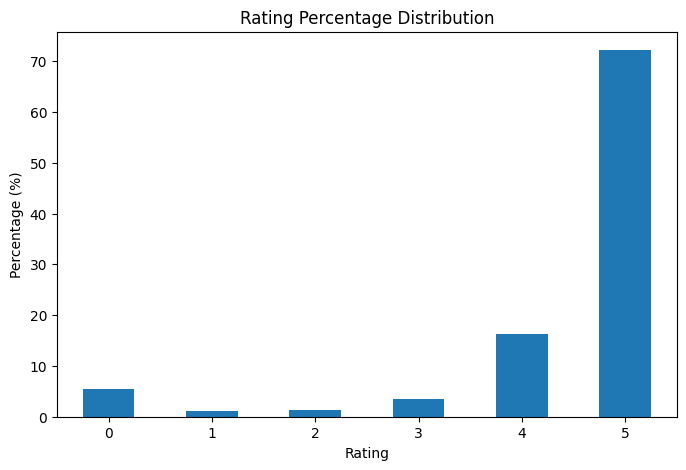


Number of Rating = 0: 76248
Number of Rating 1-5: 1325734


In [116]:
# Rating Analysis
# Rating Frequency
rating_counts = reviews["Rating"].value_counts().sort_index()

rating_summary = pd.DataFrame({
    "Count": rating_counts,
    "Percentage": rating_counts / len(reviews) * 100
})

display(rating_summary.round(2))

# Rating Percentage
plt.figure(figsize=(8, 5))

rating_summary["Percentage"].plot(kind="bar")

plt.title("Rating Percentage Distribution")
plt.xlabel("Rating")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()

# Check Rating = 0
print("\nNumber of Rating = 0:",
      (reviews["Rating"] == 0).sum())

print("Number of Rating 1-5:",
      reviews["Rating"].between(1, 5).sum())

Total Users: 271907
Total User Reviews: 1401982

Number of Reviews per User:


,Number of Users
1,199808
2,27067
3,11243
4,6106
5,4114
6,2890
7,2256
8,1763
9,1487
10,1227



Users with at least 5 Reviews: 27683
Users with fewer than 5 Reviews: 244224


,Number of Users,Percentage (%)
1,199808,73.48
2,27067,9.95
3,11243,4.13
4,6106,2.25
5+,27683,10.18


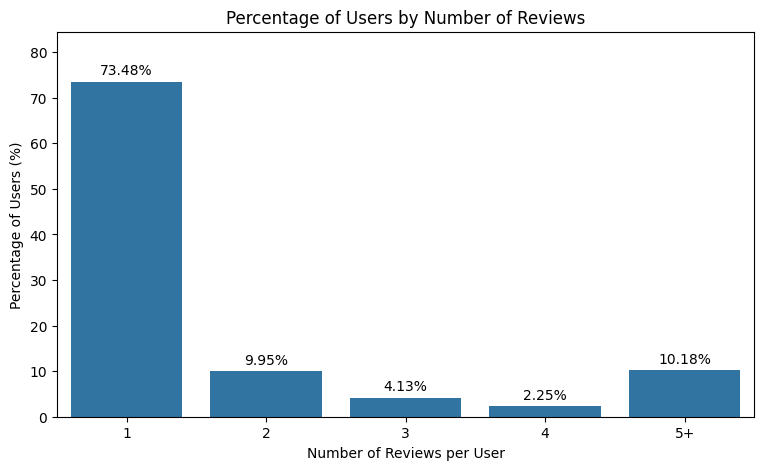

In [117]:
# User Analysis
# Reviews per User
user_review_counts = reviews.groupby("AuthorId").size()

print("Total Users:", reviews["AuthorId"].nunique())
print("Total User Reviews:", user_review_counts.sum())

# User Review Frequency
user_frequency = (
    user_review_counts.value_counts()
    .sort_index()
)

print("\nNumber of Reviews per User:")
display(user_frequency.head(20).to_frame("Number of Users"))

# Users with at least 5 reviews
print("\nUsers with at least 5 Reviews:",
      (user_review_counts >= 5).sum())

print("Users with fewer than 5 Reviews:",
      (user_review_counts < 5).sum())

# User Review Frequency Analysis

# นับจำนวนรีวิวของแต่ละ User
user_review_counts = reviews.groupby("AuthorId").size()

# แบ่งกลุ่มจำนวนรีวิว
user_review_groups = user_review_counts.clip(upper=5)

user_group_counts = (
    user_review_groups
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

# เปลี่ยนชื่อกลุ่ม 5 เป็น 5+
user_group_counts.index = ["1", "2", "3", "4", "5+"]

# คำนวณสัดส่วน
user_group_percentages = (
    user_group_counts / len(user_review_counts) * 100
)

# สร้างตารางสรุป
user_group_summary = pd.DataFrame({
    "Number of Users": user_group_counts,
    "Percentage (%)": user_group_percentages
})

display(user_group_summary.round(2))

# Bar Chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=user_group_summary.index,
    y=user_group_summary["Percentage (%)"]
)

# แสดงตัวเลขบนแท่งกราฟ
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Percentage of Users by Number of Reviews")
plt.xlabel("Number of Reviews per User")
plt.ylabel("Percentage of Users (%)")
plt.ylim(0, user_group_percentages.max() * 1.15)

plt.show()

In [118]:
# Recipe Analysis
# Reviews per Recipe
recipe_review_counts = reviews.groupby("RecipeId").size()

print("Total Recipes in Recipes Dataset:",
      recipes["RecipeId"].nunique())

print("Recipes with Reviews:",
      reviews["RecipeId"].nunique())

print("Number of Categories:", recipes["RecipeCategory"].nunique())

print("\nTop 20 Recipe Categories:")
print(recipes["RecipeCategory"].value_counts().head(20))

# Top 15 Most Reviewed Recipes
top_recipes = (
    recipe_review_counts
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

top_recipes.columns = ["RecipeId", "ReviewCount"]

top_recipes = top_recipes.merge(
    recipes[["RecipeId", "Name"]],
    on="RecipeId",
    how="left"
)

print("\nTop 15 Most Reviewed Recipes:")
display(top_recipes[["RecipeId", "Name", "ReviewCount"]])

Total Recipes in Recipes Dataset: 522517
Recipes with Reviews: 271678
Number of Categories: 311

Top 20 Recipe Categories:
RecipeCategory
Dessert           62072
Lunch/Snacks      32586
One Dish Meal     31345
Vegetable         27231
Breakfast         21101
Beverages         16076
Chicken           13249
Meat              13131
Breads            12804
Pork              12603
Sauces            12166
Chicken Breast    11282
Potato            10870
Quick Breads      10387
< 60 Mins          9719
< 30 Mins          9020
Cheese             8462
Pie                7775
Bar Cookie         7029
Low Protein        6663
Name: count, dtype: int64

Top 15 Most Reviewed Recipes:


,RecipeId,Name,ReviewCount
0,45809,Bourbon Chicken,2892
1,2886,Best Banana Bread,2182
2,27208,To Die for Crock Pot Roast,1614
3,89204,Crock-Pot Chicken With Black Beans &amp; Cream...,1584
4,39087,Creamy Cajun Chicken Pasta,1491
5,67256,Best Ever Banana Cake With Cream Cheese Frosting,1359
6,35813,Oatmeal Raisin Cookies,1353
7,54257,"Yes, Virginia There is a Great Meatloaf",1325
8,22782,Jo Mama's World Famous Spaghetti,1273
9,32204,&quot;Whatever Floats Your Boat&quot; Brownies!,1228


In [119]:
# Interaction Analysis
# Number of Users and Items
n_users = reviews["AuthorId"].nunique()
n_items = reviews["RecipeId"].nunique()
n_interactions = len(reviews)

# Possible Interactions
possible_interactions = n_users * n_items

# Density and Sparsity
density = n_interactions / possible_interactions
sparsity = 1 - density

print("Number of Users:", n_users)
print("Number of Recipes:", n_items)
print("Number of Interactions:", n_interactions)
print("Possible Interactions:", possible_interactions)

print("\nDensity:", round(density * 100, 6), "%")
print("Sparsity:", round(sparsity * 100, 6), "%")

Number of Users: 271907
Number of Recipes: 271678
Number of Interactions: 1401982
Possible Interactions: 73871149946

Density: 0.001898 %
Sparsity: 99.998102 %


Missing Dates: 0
Earliest Review Date: 2000-01-25 21:44:00+00:00
Latest Review Date: 2020-12-28 03:23:48+00:00

Reviews per Year:


,Number of Reviews
DateSubmitted,
2000,156
2001,3904
2002,27572
2003,43820
2004,59549
2005,84913
2006,111991
2007,173397
2008,202979


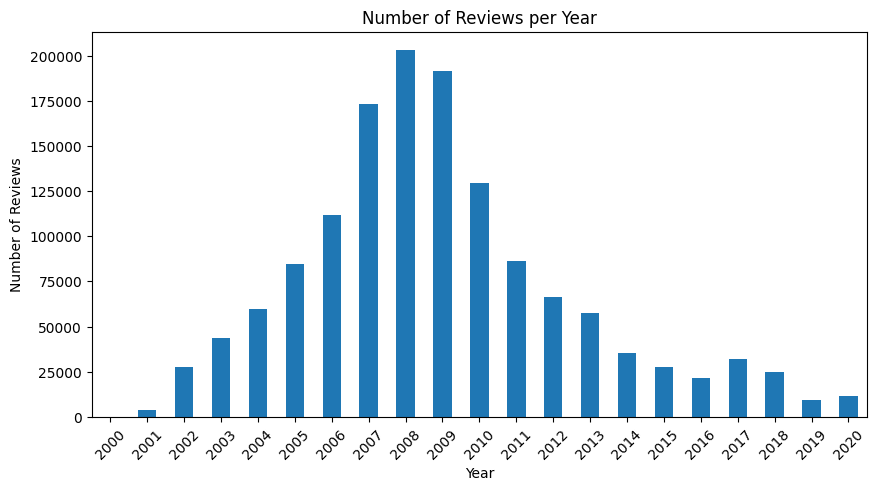

In [120]:
# Temporal Analysis
# Convert DateSubmitted to Datetime
review_dates = pd.to_datetime(
    reviews["DateSubmitted"],
    errors="coerce",
    utc=True
)

print("Missing Dates:", review_dates.isna().sum())

print("Earliest Review Date:", review_dates.min())
print("Latest Review Date:", review_dates.max())

# Reviews per Year
reviews_by_year = (
    review_dates
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nReviews per Year:")
display(reviews_by_year.to_frame("Number of Reviews"))

# Plot Reviews per Year
plt.figure(figsize=(10, 5))

reviews_by_year.plot(kind="bar")

plt.title("Number of Reviews per Year")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.show()

In [121]:
# EDA Summary
print("Total Recipes:", recipes["RecipeId"].nunique())
print("Total Reviews:", len(reviews))
print("Total Users:", reviews["AuthorId"].nunique())
print("Total Reviewed Recipes:", reviews["RecipeId"].nunique())

print("\nRating = 0:", (reviews["Rating"] == 0).sum())
print("Rating 1-5:", reviews["Rating"].between(1, 5).sum())

print("\nUsers with at least 5 reviews:",
      (user_review_counts >= 5).sum())

print("Recipes with Reviews:",
      recipe_review_counts.shape[0])

print("\nUser-Item Density:", round(density * 100, 6), "%")
print("User-Item Sparsity:", round(sparsity * 100, 6), "%")

print("\nMissing Review Dates:", review_dates.isna().sum())

Total Recipes: 522517
Total Reviews: 1401982
Total Users: 271907
Total Reviewed Recipes: 271678

Rating = 0: 76248
Rating 1-5: 1325734

Users with at least 5 reviews: 27683
Recipes with Reviews: 271678

User-Item Density: 0.001898 %
User-Item Sparsity: 99.998102 %

Missing Review Dates: 0


# Data Preprocessing

In [122]:
print("=== Data Selection & Cleaning ===")

# Keep original datasets unchanged
recipes_clean = recipes.copy()

# Select necessary columns from Reviews
reviews_clean = reviews[
    ["ReviewId", "AuthorId", "RecipeId", "Rating", "DateSubmitted"]
].copy()

# Convert DateSubmitted to datetime
reviews_clean["DateSubmitted"] = pd.to_datetime(
    reviews_clean["DateSubmitted"],
    errors="coerce",
    utc=True
)

# Remove rows with missing essential values
reviews_clean = reviews_clean.dropna(
    subset=["AuthorId", "RecipeId", "Rating", "DateSubmitted"]
).copy()

# Keep only valid ratings (1-5)
rating_zero_count = (reviews_clean["Rating"] == 0).sum()

reviews_clean = reviews_clean[
    reviews_clean["Rating"].between(1, 5)
].copy()

# Keep only reviews whose RecipeId exists in Recipes
reviews_clean = reviews_clean[
    reviews_clean["RecipeId"].isin(recipes_clean["RecipeId"])
].copy()

print("Original Reviews:", reviews.shape)
print("Cleaned Reviews:", reviews_clean.shape)
print("Original Recipes:", recipes.shape)
print("Rating = 0 removed:", rating_zero_count)
print("Missing values after cleaning:")
print(reviews_clean.isnull().sum())

=== Data Selection & Cleaning ===
Original Reviews: (1401982, 8)
Cleaned Reviews: (1325716, 5)
Original Recipes: (522517, 28)
Rating = 0 removed: 76248
Missing values after cleaning:
ReviewId         0
AuthorId         0
RecipeId         0
Rating           0
DateSubmitted    0
dtype: int64


In [123]:
print("\n=== Recipe Data Preparation ===")

# Select recipe information for Content-Based
recipe_cols = [
    "RecipeId",
    "Name",
    "RecipeCategory",
    "Keywords",
    "RecipeIngredientParts"
]

recipes_clean = recipes_clean[recipe_cols].copy()

# Handle missing values in content features
content_cols = [
    "Name",
    "RecipeCategory",
    "Keywords",
    "RecipeIngredientParts"
]

recipes_clean[content_cols] = recipes_clean[content_cols].fillna("")

# Sort recipes by RecipeId
recipes_clean = recipes_clean.sort_values(
    "RecipeId"
).reset_index(drop=True)

print("Recipes available for recommendation:", len(recipes_clean))
print("\nMissing values:")
print(recipes_clean[content_cols].isnull().sum())

print("\nRecipe Data Sample:")
display(recipes_clean.head())


=== Recipe Data Preparation ===
Recipes available for recommendation: 522517

Missing values:
Name                     0
RecipeCategory           0
Keywords                 0
RecipeIngredientParts    0
dtype: int64

Recipe Data Sample:


,RecipeId,Name,RecipeCategory,Keywords,RecipeIngredientParts
0,38,Low-Fat Berry Blue Frozen Dessert,Frozen Desserts,"c(""Dessert"", ""Low Protein"", ""Low Cholesterol"",...","c(""blueberries"", ""granulated sugar"", ""vanilla ..."
1,39,Biryani,Chicken Breast,"c(""Chicken Thigh & Leg"", ""Chicken"", ""Poultry"",...","c(""saffron"", ""milk"", ""hot green chili peppers""..."
2,40,Best Lemonade,Beverages,"c(""Low Protein"", ""Low Cholesterol"", ""Healthy"",...","c(""sugar"", ""lemons, rind of"", ""lemon, zest of""..."
3,41,Carina's Tofu-Vegetable Kebabs,Soy/Tofu,"c(""Beans"", ""Vegetable"", ""Low Cholesterol"", ""We...","c(""extra firm tofu"", ""eggplant"", ""zucchini"", ""..."
4,42,Cabbage Soup,Vegetable,"c(""Low Protein"", ""Vegan"", ""Low Cholesterol"", ""...","c(""plain tomato juice"", ""cabbage"", ""onion"", ""c..."


In [124]:
print("\n=== Content Feature Engineering ===")

# Clean text from recipe fields
def clean_r_vector(text):
    text = str(text)
    text = re.sub(r'^c\(|\)$', '', text)
    text = text.replace('"', '').replace(',', ' ')
    return ' '.join(text.split()).lower()

# Clean recipe name and category
recipes_clean["Name_clean"] = (
    recipes_clean["Name"].str.lower().str.strip()
)

recipes_clean["Category_clean"] = (
    recipes_clean["RecipeCategory"].str.lower().str.strip()
)

# Clean keywords and ingredients
recipes_clean["Keywords_clean"] = (
    recipes_clean["Keywords"].apply(clean_r_vector)
)

recipes_clean["Ingredients_clean"] = (
    recipes_clean["RecipeIngredientParts"].apply(clean_r_vector)
)

# Main content features
recipes_clean["content_base"] = (
    recipes_clean["Name_clean"] + " " +
    recipes_clean["Category_clean"] + " " +
    recipes_clean["Keywords_clean"]
).str.strip()

# Additional content features for model improvement
recipes_clean["content_with_ingredients"] = (
    recipes_clean["content_base"] + " " +
    recipes_clean["Ingredients_clean"]
).str.strip()

print("Content features created successfully.")

print("\nContent Feature Sample:")
display(
    recipes_clean[
        ["RecipeId", "content_base", "content_with_ingredients"]
    ].head()
)


=== Content Feature Engineering ===
Content features created successfully.

Content Feature Sample:


,RecipeId,content_base,content_with_ingredients
0,38,low-fat berry blue frozen dessert frozen desse...,low-fat berry blue frozen dessert frozen desse...
1,39,biryani chicken breast chicken thigh & leg chi...,biryani chicken breast chicken thigh & leg chi...
2,40,best lemonade beverages low protein low choles...,best lemonade beverages low protein low choles...
3,41,carina's tofu-vegetable kebabs soy/tofu beans ...,carina's tofu-vegetable kebabs soy/tofu beans ...
4,42,cabbage soup vegetable low protein vegan low c...,cabbage soup vegetable low protein vegan low c...


In [125]:
print("\n=== Active User Filtering ===")

# Count valid reviews per user
user_review_counts = reviews_clean.groupby("AuthorId").size()

# Keep users with at least 5 reviews
active_user_ids = user_review_counts[
    user_review_counts >= 5
].index

reviews_clean = reviews_clean[
    reviews_clean["AuthorId"].isin(active_user_ids)
].copy()

print("Number of active users:", reviews_clean["AuthorId"].nunique())
print("Reviews after active user filtering:", len(reviews_clean))
print("Minimum reviews per user:", reviews_clean.groupby("AuthorId").size().min())


=== Active User Filtering ===
Number of active users: 26400
Reviews after active user filtering: 1055922
Minimum reviews per user: 5


In [126]:
print("\n=== ID Mapping ===")

# Create User ID mapping
user_id_map = {
    uid: idx
    for idx, uid in enumerate(reviews_clean["AuthorId"].unique())
}

# Create Item ID mapping using the full recipe catalog
item_id_map = {
    rid: idx
    for idx, rid in enumerate(recipes_clean["RecipeId"].unique())
}

# Map original IDs to numerical IDs
reviews_clean["user_idx"] = reviews_clean["AuthorId"].map(user_id_map)
reviews_clean["item_idx"] = reviews_clean["RecipeId"].map(item_id_map)

recipes_clean["item_idx"] = recipes_clean["RecipeId"].map(item_id_map)

# Reorder review columns
reviews_clean = reviews_clean[
    [
        "user_idx",
        "item_idx",
        "ReviewId",
        "RecipeId",
        "AuthorId",
        "Rating",
        "DateSubmitted"
    ]
].copy()

print("Number of users:", len(user_id_map))
print("Number of recipes:", len(item_id_map))

print("\nReviews Mapping Sample:")
display(reviews_clean.head())

print("\nRecipes Mapping Sample:")
display(recipes_clean[["RecipeId", "item_idx"]].head())


=== ID Mapping ===
Number of users: 26400
Number of recipes: 522517

Reviews Mapping Sample:


,user_idx,item_idx,ReviewId,RecipeId,AuthorId,Rating,DateSubmitted
1,0,2772,7,4384,1634,4,2001-10-17 16:49:59+00:00
2,1,2886,9,4523,2046,2,2000-02-25 09:00:00+00:00
3,2,4593,13,7435,1773,5,2000-03-13 21:15:00+00:00
5,1,3454,17,5221,2046,4,2000-05-08 11:08:00+00:00
6,1,10122,19,13307,2046,5,2000-05-21 16:59:00+00:00



Recipes Mapping Sample:


,RecipeId,item_idx
0,38,0
1,39,1
2,40,2
3,41,3
4,42,4


# Train / Test Split

In [127]:
print("\n=== Train/Test Split ===")

# Sort reviews chronologically for each user
reviews_clean = reviews_clean.sort_values(
    ["AuthorId", "DateSubmitted", "ReviewId"]
).reset_index(drop=True)

train_parts = []
test_parts = []

# Split each user's reviews into 80% Train and 20% Test
for user_id, group in reviews_clean.groupby("AuthorId", sort=False):

    train_size = int(np.floor(len(group) * 0.8))

    train_parts.append(group.iloc[:train_size])
    test_parts.append(group.iloc[train_size:])

# Combine all users' data
train_data = pd.concat(train_parts).reset_index(drop=True)
test_data = pd.concat(test_parts).reset_index(drop=True)

print("Train Shape:", train_data.shape)
print("Test Shape:", test_data.shape)

print("Train Percentage:",
      round(len(train_data) / len(reviews_clean) * 100, 2), "%")

print("Test Percentage:",
      round(len(test_data) / len(reviews_clean) * 100, 2), "%")

print("\nTrain Date Range:")
print(train_data["DateSubmitted"].min(), "to",
      train_data["DateSubmitted"].max())

print("\nTest Date Range:")
print(test_data["DateSubmitted"].min(), "to",
      test_data["DateSubmitted"].max())


=== Train/Test Split ===
Train Shape: (834555, 7)
Test Shape: (221367, 7)
Train Percentage: 79.04 %
Test Percentage: 20.96 %

Train Date Range:
2000-02-25 09:00:00+00:00 to 2020-12-24 20:59:49+00:00

Test Date Range:
2000-12-04 10:53:16+00:00 to 2020-12-27 21:51:56+00:00


In [128]:
print("\n=== Preprocessing Validation ===")

# Check missing values
print("Missing Values in Train:")
print(train_data.isnull().sum())

print("\nMissing Values in Test:")
print(test_data.isnull().sum())

# Check user overlap
train_users = set(train_data["AuthorId"].unique())
test_users = set(test_data["AuthorId"].unique())

print("\nUsers in Train:", len(train_users))
print("Users in Test:", len(test_users))
print("Users appearing in both:", len(train_users.intersection(test_users)))

# Check chronological order for each user
train_latest = train_data.groupby("AuthorId")["DateSubmitted"].max()
test_earliest = test_data.groupby("AuthorId")["DateSubmitted"].min()

temporal_check = (train_latest <= test_earliest).all()

print("Temporal Order Valid:", temporal_check)

# Check rating distribution
print("\nTrain Rating Distribution:")
print(train_data["Rating"].value_counts().sort_index())

print("\nTest Rating Distribution:")
print(test_data["Rating"].value_counts().sort_index())

# Check duplicate user-recipe interactions
print("\nDuplicate User-Recipe Pairs in Train:",
      train_data.duplicated(["AuthorId", "RecipeId"]).sum())

print("Duplicate User-Recipe Pairs in Test:",
      test_data.duplicated(["AuthorId", "RecipeId"]).sum())

# Check item mapping alignment
mapping_check = (
    recipes_clean["item_idx"].to_numpy() == np.arange(len(recipes_clean))
).all()

print("\nRecipe Item Mapping Alignment:", mapping_check)

# Final summary
print("\n=== Final Preprocessing Summary ===")
print("Total Recipes:", len(recipes_clean))
print("Total Active Users:", reviews_clean["AuthorId"].nunique())
print("Total Valid Reviews:", len(reviews_clean))
print("Train Interactions:", len(train_data))
print("Test Interactions:", len(test_data))
print("Number of Content Features:", 2)


=== Preprocessing Validation ===
Missing Values in Train:
user_idx         0
item_idx         0
ReviewId         0
RecipeId         0
AuthorId         0
Rating           0
DateSubmitted    0
dtype: int64

Missing Values in Test:
user_idx         0
item_idx         0
ReviewId         0
RecipeId         0
AuthorId         0
Rating           0
DateSubmitted    0
dtype: int64

Users in Train: 26400
Users in Test: 26400
Users appearing in both: 26400
Temporal Order Valid: True

Train Rating Distribution:
Rating
1      4831
2      9028
3     32583
4    156351
5    631762
Name: count, dtype: int64

Test Rating Distribution:
Rating
1      1369
2      2113
3      7187
4     34857
5    175841
Name: count, dtype: int64

Duplicate User-Recipe Pairs in Train: 0
Duplicate User-Recipe Pairs in Test: 0

Recipe Item Mapping Alignment: True

=== Final Preprocessing Summary ===
Total Recipes: 522517
Total Active Users: 26400
Total Valid Reviews: 1055922
Train Interactions: 834555
Test Interactions: 2213

# Model 1: Popularity (Baseline)

Popularity Score Calculation

In [129]:
print("=== Popularity Score Calculation ===")

# --------------------------------------------------
# 1. Set Popularity Parameters
# --------------------------------------------------

k_val = 10
min_votes_val = 3

# --------------------------------------------------
# 2. Calculate Rating Statistics from Train Set
# --------------------------------------------------

popularity_stats = (
    train_data.groupby("RecipeId")
    .agg(
        vote_count=("Rating", "count"),
        vote_average=("Rating", "mean")
    )
    .reset_index()
)

# --------------------------------------------------
# 3. Combine Rating Statistics with Recipe Information
# --------------------------------------------------

popularity_catalog = recipes_clean.merge(
    popularity_stats,
    on="RecipeId",
    how="inner"
)

# --------------------------------------------------
# 4. Filter Recipes with Minimum Number of Reviews
# --------------------------------------------------

popularity_filtered = popularity_catalog[
    popularity_catalog["vote_count"] >= min_votes_val
].copy()

# --------------------------------------------------
# 5. Rank Recipes by Average Rating and Vote Count
# --------------------------------------------------

popularity_sorted = popularity_filtered.sort_values(
    by=["vote_average", "vote_count"],
    ascending=[False, False]
).reset_index(drop=True)

# --------------------------------------------------
# 6. Display Top 10 Popular Recipes
# --------------------------------------------------

top_10_popularity = popularity_sorted[
    [
        "RecipeId",
        "Name",
        "RecipeCategory",
        "vote_count",
        "vote_average"
    ]
].head(k_val).copy()

top_10_popularity.insert(
    0,
    "Rank",
    range(1, len(top_10_popularity) + 1)
)

print("\n=== Top 10 Popular Recipes (Baseline) ===")
display(top_10_popularity)

print("\n=== Popularity Statistics ===")
print("Recipes with Rating Statistics:", len(popularity_catalog))
print("Recipes after Minimum Review Filter:", len(popularity_filtered))
print("Minimum Required Reviews:", min_votes_val)

=== Popularity Score Calculation ===

=== Top 10 Popular Recipes (Baseline) ===


,Rank,RecipeId,Name,RecipeCategory,vote_count,vote_average
0,1,16399,Quinoa-Toasted,Grains,58,5.0
1,2,77497,2- Handed Kitchen Sink Tomato Sandwich,Lunch/Snacks,56,5.0
2,3,87689,Cake Flour Substitute,Vegan,54,5.0
3,4,154351,Kittencal's Balsamic Vinaigrette,Salad Dressings,50,5.0
4,5,61948,Toasted Almond,Beverages,43,5.0
5,6,55309,Caprese Salad Tomatoes (Italian Marinated Toma...,Vegetable,41,5.0
6,7,186029,The Best Creole/Cajun Seasoning Mix,Cajun,41,5.0
7,8,73710,Roasted Garlic Paste,Spreads,39,5.0
8,9,31639,7 Layer Bean Dip,Mexican,38,5.0
9,10,65271,Homemade Brown Sugar,Low Protein,37,5.0



=== Popularity Statistics ===
Recipes with Rating Statistics: 215713
Recipes after Minimum Review Filter: 75037
Minimum Required Reviews: 3


Recommendation Function

In [130]:
print("=== Recommendation Function ===")


def recommend_popularity_based(
    author_id,
    train_df,
    popularity_df,
    top_n=10
):

    # --------------------------------------------------
    # 1. Get Previously Reviewed Recipes
    # --------------------------------------------------

    seen_recipes = set(
        train_df.loc[
            train_df["AuthorId"] == author_id,
            "RecipeId"
        ]
    )

    # --------------------------------------------------
    # 2. Exclude Previously Reviewed Recipes
    # --------------------------------------------------

    candidate_recipes = popularity_df[
        ~popularity_df["RecipeId"].isin(seen_recipes)
    ].copy()

    # --------------------------------------------------
    # 3. Select Top-N Popular Recipes
    # --------------------------------------------------

    recommended_recipes = candidate_recipes.head(
        top_n
    ).copy()

    # --------------------------------------------------
    # 4. Add Recommendation Rank
    # --------------------------------------------------

    recommended_recipes.insert(
        0,
        "Rank",
        range(1, len(recommended_recipes) + 1)
    )

    return recommended_recipes[
        [
            "Rank",
            "RecipeId",
            "Name",
            "RecipeCategory",
            "vote_count",
            "vote_average"
        ]
    ].reset_index(drop=True)


# --------------------------------------------------
# 5. Test Recommendation Function
# --------------------------------------------------

sample_user_id = 140132

sample_popularity_recommendations = recommend_popularity_based(
    author_id=sample_user_id,
    train_df=train_data,
    popularity_df=popularity_sorted,
    top_n=10
)

print("\n=== Recommendation Function Test ===")
print("Sample User ID:", sample_user_id)
print(
    "Recommended Recipes:",
    len(sample_popularity_recommendations)
)

=== Recommendation Function ===

=== Recommendation Function Test ===
Sample User ID: 140132
Recommended Recipes: 10


Model Evaluation, Recommendation Example & Validation

In [131]:
print("=== Model Evaluation ===")

# --------------------------------------------------
# 1. Initialize Evaluation Metrics
# --------------------------------------------------

pop_precisions_5 = []
pop_recalls_5 = []

pop_precisions_10 = []
pop_recalls_10 = []

# --------------------------------------------------
# 2. Evaluate the Same 1,000 Users
# --------------------------------------------------

for user_id in sample_eval_users:

    recommendations = recommend_popularity_based(
        author_id=user_id,
        train_df=train_data,
        popularity_df=popularity_sorted,
        top_n=10
    )

    recommended_ids = recommendations["RecipeId"].tolist()

    relevant_items = user_ground_truth[user_id]

    # Top 5 and Top 10
    top_5 = set(recommended_ids[:5])
    top_10 = set(recommended_ids[:10])

    # Calculate Hits
    hits_5 = len(top_5.intersection(relevant_items))
    hits_10 = len(top_10.intersection(relevant_items))

    # Calculate Precision
    precision_5 = hits_5 / 5
    precision_10 = hits_10 / 10

    # Calculate Recall
    recall_5 = hits_5 / len(relevant_items)
    recall_10 = hits_10 / len(relevant_items)

    pop_precisions_5.append(precision_5)
    pop_recalls_5.append(recall_5)

    pop_precisions_10.append(precision_10)
    pop_recalls_10.append(recall_10)


# --------------------------------------------------
# 3. Display Evaluation Results
# --------------------------------------------------

print("\n=== Popularity-Based Model Evaluation ===")

print("Top-5 Recommendations:")
print(f"Precision@5 : {np.mean(pop_precisions_5):.6f}")
print(f"Recall@5    : {np.mean(pop_recalls_5):.6f}")

print("\nTop-10 Recommendations:")
print(f"Precision@10: {np.mean(pop_precisions_10):.6f}")
print(f"Recall@10   : {np.mean(pop_recalls_10):.6f}")


# --------------------------------------------------
# 4. Check Users with Matching Recommendations
# --------------------------------------------------

users_with_hits_5 = sum(
    np.array(pop_precisions_5) > 0
)

users_with_hits_10 = sum(
    np.array(pop_precisions_10) > 0
)

print("\n=== Evaluation Summary ===")

print("Total Evaluation Users:", len(sample_eval_users))

print("Users with Hits@5:", users_with_hits_5)
print("Users with No Hits@5:",
      len(sample_eval_users) - users_with_hits_5)

print("Users with Hits@10:", users_with_hits_10)
print("Users with No Hits@10:",
      len(sample_eval_users) - users_with_hits_10)

=== Model Evaluation ===

=== Popularity-Based Model Evaluation ===
Top-5 Recommendations:
Precision@5 : 0.001400
Recall@5    : 0.001233

Top-10 Recommendations:
Precision@10: 0.000800
Recall@10   : 0.001733

=== Evaluation Summary ===
Total Evaluation Users: 1000
Users with Hits@5: 7
Users with No Hits@5: 993
Users with Hits@10: 8
Users with No Hits@10: 992


Recommendation Example — User 140132

In [132]:
print("=== Recommendation Example ===")

sample_user_id = 140132

# --------------------------------------------------
# 1. Generate Top-10 Recommendations
# --------------------------------------------------

sample_popularity_recommendations = recommend_popularity_based(
    author_id=sample_user_id,
    train_df=train_data,
    popularity_df=popularity_sorted,
    top_n=10
)

print("\n=== Top 10 Popularity-Based Recommendations ===")
print("Sample User ID:", sample_user_id)

display(sample_popularity_recommendations)


# --------------------------------------------------
# 2. Display Recipes Actually Liked in Test
# --------------------------------------------------

actual_liked = (
    test_data[
        (test_data["AuthorId"] == sample_user_id) &
        (test_data["Rating"] >= 4)
    ]
    .merge(
        recipes_clean[
            ["RecipeId", "Name", "RecipeCategory"]
        ],
        on="RecipeId",
        how="left"
    )
)

print("\n=== Recipes Actually Liked in Test ===")

display(
    actual_liked[
        ["RecipeId", "Name", "RecipeCategory", "Rating"]
    ]
)


# --------------------------------------------------
# 3. Check Matching Recommendations
# --------------------------------------------------

recommended_ids = set(
    sample_popularity_recommendations["RecipeId"]
)

actual_liked_ids = set(
    actual_liked["RecipeId"]
)

matching_ids = recommended_ids.intersection(
    actual_liked_ids
)

print("\n=== Recommendation Matching ===")

print("Recommended Recipes:", len(recommended_ids))
print("Actually Liked Recipes:", len(actual_liked_ids))
print("Matching Recommendations:", len(matching_ids))

=== Recommendation Example ===

=== Top 10 Popularity-Based Recommendations ===
Sample User ID: 140132


,Rank,RecipeId,Name,RecipeCategory,vote_count,vote_average
0,1,16399,Quinoa-Toasted,Grains,58,5.0
1,2,77497,2- Handed Kitchen Sink Tomato Sandwich,Lunch/Snacks,56,5.0
2,3,87689,Cake Flour Substitute,Vegan,54,5.0
3,4,154351,Kittencal's Balsamic Vinaigrette,Salad Dressings,50,5.0
4,5,61948,Toasted Almond,Beverages,43,5.0
5,6,55309,Caprese Salad Tomatoes (Italian Marinated Toma...,Vegetable,41,5.0
6,7,186029,The Best Creole/Cajun Seasoning Mix,Cajun,41,5.0
7,8,65271,Homemade Brown Sugar,Low Protein,37,5.0
8,9,66032,Root Beer Float!,Beverages,37,5.0
9,10,82770,Italian Seasoning (Old Sub Sailor),European,35,5.0



=== Recipes Actually Liked in Test ===


,RecipeId,Name,RecipeCategory,Rating
0,147857,Meatballs &amp; Lil' Smokies Appetizer Snack,Lunch/Snacks,4
1,62233,Gooey Monkey Bread,Yeast Breads,5
2,117317,Blue Ridge Mountains Chocolate Chip Cookies,Drop Cookies,5
3,98869,Apple or Pear Cake,Dessert,5
4,6653,Blueberry Buttermilk Muffins,Quick Breads,5
...,...,...,...,...
502,44932,French Dip Sandwiches (For Crock Pot),Lunch/Snacks,5
503,101651,Cream Cheese Pizza Dip,Cheese,5
504,146558,Baked Ham Glazed With Pineapple and Chipotle P...,Lunch/Snacks,5
505,42402,The Best (Do-Ahead) Turkey Gravy,Sauces,5



=== Recommendation Matching ===
Recommended Recipes: 10
Actually Liked Recipes: 507
Matching Recommendations: 1


In [133]:
print("=== Model Validation ===")

# --------------------------------------------------
# 1. Train/Test & Recommendation Check
# --------------------------------------------------

user_train = train_data[
    train_data["AuthorId"] == sample_user_id
]

user_test = test_data[
    test_data["AuthorId"] == sample_user_id
]

train_recipe_ids = set(user_train["RecipeId"])
test_recipe_ids = set(user_test["RecipeId"])

recommended_ids = set(
    sample_popularity_recommendations["RecipeId"]
)

print("\n--- Train/Test & Recommendation Check ---")

print("Train Recipes:", len(train_recipe_ids))
print("Test Recipes:", len(test_recipe_ids))

print("Train-Test Overlap:",
      len(train_recipe_ids.intersection(test_recipe_ids)))

print("Recommended Recipes:", len(recommended_ids))

print("Recommendations Already in Train:",
      len(recommended_ids.intersection(train_recipe_ids)))


# --------------------------------------------------
# 2. Popularity Score Validation
# --------------------------------------------------

print("\n--- Popularity Score Check ---")

print("All Vote Counts Meet Minimum Requirement:",
      (popularity_sorted["vote_count"] >= min_votes_val).all())

print("All Average Ratings Are Finite:",
      np.isfinite(popularity_sorted["vote_average"]).all())

print("All Average Ratings Within Valid Range:",
      popularity_sorted["vote_average"].between(1, 5).all())

print("All Vote Counts Are Positive:",
      (popularity_sorted["vote_count"] > 0).all())


# --------------------------------------------------
# 3. Recommendation Ranking Validation
# --------------------------------------------------

sample_scores = sample_popularity_recommendations[
    ["vote_average", "vote_count"]
].to_numpy()

ranking_is_correct = True

for i in range(len(sample_scores) - 1):

    current_rating, current_votes = sample_scores[i]
    next_rating, next_votes = sample_scores[i + 1]

    if (
        current_rating < next_rating
        or (
            current_rating == next_rating
            and current_votes < next_votes
        )
    ):
        ranking_is_correct = False
        break

print("\n--- Recommendation Ranking Check ---")

print("Recommendations Sorted Correctly:",
      ranking_is_correct)

print("Recommendations Are Unique:",
      sample_popularity_recommendations["RecipeId"].is_unique)

print("\n=== Popularity-Based Validation Completed ===")

=== Model Validation ===

--- Train/Test & Recommendation Check ---
Train Recipes: 2036
Test Recipes: 509
Train-Test Overlap: 0
Recommended Recipes: 10
Recommendations Already in Train: 0

--- Popularity Score Check ---
All Vote Counts Meet Minimum Requirement: True
All Average Ratings Are Finite: True
All Average Ratings Within Valid Range: True
All Vote Counts Are Positive: True

--- Recommendation Ranking Check ---
Recommendations Sorted Correctly: True
Recommendations Are Unique: True

=== Popularity-Based Validation Completed ===


# Model 2: Content-Based Recommendation

TF-IDF & User Profile

In [134]:
print("=== TF-IDF & User Profile ===")

# --------------------------------------------------
# 1. Create TF-IDF Matrix
# --------------------------------------------------

print("Processing TF-IDF for Recipes...")

tfidf_base = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_matrix_base = tfidf_base.fit_transform(
    recipes_clean["content_base"]
)

print("\n=== TF-IDF Matrix Information ===")
print("Total Recipes:", tfidf_matrix_base.shape[0])
print("Total Features:", tfidf_matrix_base.shape[1])
print("Matrix Shape:", tfidf_matrix_base.shape)


# --------------------------------------------------
# 2. Create Recipe Mapping
# --------------------------------------------------

recipe_to_idx = dict(
    zip(
        recipes_clean["RecipeId"],
        recipes_clean["item_idx"]
    )
)

idx_to_recipe = {
    idx: recipe_id
    for recipe_id, idx in recipe_to_idx.items()
}


# --------------------------------------------------
# 3. Build User Profile
# --------------------------------------------------

def build_user_profile(
    author_id,
    tfidf_matrix,
    train_df,
    recipe_to_idx
):

    # Select recipes rated >= 4 in Train
    user_train = train_df[
        (train_df["AuthorId"] == author_id) &
        (train_df["Rating"] >= 4)
    ]

    if user_train.empty:
        return None, set()

    # Get Recipe IDs
    user_recipes = user_train["RecipeId"].tolist()

    # Convert Recipe IDs to TF-IDF indices
    user_item_indices = [
        recipe_to_idx[rid]
        for rid in user_recipes
        if rid in recipe_to_idx
    ]

    if not user_item_indices:
        return None, set()

    # Average TF-IDF vectors to create User Profile
    user_profile = np.asarray(
        tfidf_matrix[user_item_indices].mean(axis=0)
    )

    return user_profile, set(user_item_indices)


# --------------------------------------------------
# 4. Test User Profile
# --------------------------------------------------

sample_user_id = 140132

sample_profile, sample_seen_indices = build_user_profile(
    sample_user_id,
    tfidf_matrix_base,
    train_data,
    recipe_to_idx
)

print("\n=== User Profile Example ===")
print("Sample User ID:", sample_user_id)

if sample_profile is not None:
    print("User Profile Created: True")
    print("User Profile Shape:", sample_profile.shape)
    print("Liked Recipes Used:", len(sample_seen_indices))
else:
    print("User Profile Created: False")


=== TF-IDF & User Profile ===
Processing TF-IDF for Recipes...

=== TF-IDF Matrix Information ===
Total Recipes: 522517
Total Features: 5000
Matrix Shape: (522517, 5000)

=== User Profile Example ===
Sample User ID: 140132
User Profile Created: True
User Profile Shape: (1, 5000)
Liked Recipes Used: 2001


Recommendation Function

In [135]:

print("=== Recommendation Function ===")


def recommend_content_based(
    author_id,
    tfidf_matrix,
    train_df,
    recipes_df,
    recipe_to_idx,
    idx_to_recipe,
    k_rec=10
):

    # --------------------------------------------------
    # 1. Build User Profile
    # --------------------------------------------------

    user_profile, seen_indices = build_user_profile(
        author_id,
        tfidf_matrix,
        train_df,
        recipe_to_idx
    )

    if user_profile is None:
        return []

    # --------------------------------------------------
    # 2. Calculate Cosine Similarity
    # --------------------------------------------------

    sim_scores = linear_kernel(
        user_profile,
        tfidf_matrix
    ).flatten()

    # --------------------------------------------------
    # 3. Exclude Recipes Already Liked in Train
    # --------------------------------------------------

    for idx in seen_indices:
        sim_scores[idx] = -1.0

    # --------------------------------------------------
    # 4. Select Top-K Recommendations
    # --------------------------------------------------

    top_indices = np.argsort(sim_scores)[::-1][:k_rec]

    # Keep only recipes with positive similarity
    top_indices = [
        idx for idx in top_indices
        if sim_scores[idx] > 0
    ]

    return top_indices


# --------------------------------------------------
# 5. Test Recommendation Function
# --------------------------------------------------

sample_user_id = 140132

top_indices_sample = recommend_content_based(
    author_id=sample_user_id,
    tfidf_matrix=tfidf_matrix_base,
    train_df=train_data,
    recipes_df=recipes_clean,
    recipe_to_idx=recipe_to_idx,
    idx_to_recipe=idx_to_recipe,
    k_rec=10
)

print("\n=== Recommendation Function Test ===")
print("Sample User ID:", sample_user_id)
print("Number of Recommendations:", len(top_indices_sample))

if top_indices_sample:

    rec_recipe_ids = [
        idx_to_recipe[idx]
        for idx in top_indices_sample
    ]

    rec_sample_df = recipes_clean[
        recipes_clean["RecipeId"].isin(rec_recipe_ids)
    ].copy()

    # Preserve recommendation ranking
    rec_sample_df["Rank"] = (
        rec_sample_df["RecipeId"]
        .map({
            idx_to_recipe[idx]: rank
            for rank, idx in enumerate(top_indices_sample, start=1)
        })
    )

    rec_sample_df = rec_sample_df.sort_values("Rank")

    display(
        rec_sample_df[
            ["Rank", "RecipeId", "Name", "RecipeCategory"]
        ].reset_index(drop=True)
    )

else:
    print("No recommendations available for this user.")


=== Recommendation Function ===

=== Recommendation Function Test ===
Sample User ID: 140132
Number of Recommendations: 10


,Rank,RecipeId,Name,RecipeCategory
0,1,60974,Hanky Pankies,Lunch/Snacks
1,2,40359,Boboli,Lunch/Snacks
2,3,17415,Chicken Mashed Potatoes,Lunch/Snacks
3,4,17694,Neeps An'tatties,Lunch/Snacks
4,5,149949,Chicken Glop,Lunch/Snacks
5,6,20198,Easy Lemon Chicken,One Dish Meal
6,7,18704,Rösti (Bernese Fried Potatoes),Lunch/Snacks
7,8,178318,Oven-Fried Chicken,Lunch/Snacks
8,9,39975,Chippy Chicken,Lunch/Snacks
9,10,63861,Too Easy Chicken,Poultry


Model Evaluation, Recommendation Example & Validation

In [136]:

print("=== Model Evaluation ===")

# --------------------------------------------------
# 1. Evaluate the Shared Sample Users
# --------------------------------------------------

precisions_cb5 = []
recalls_cb5 = []

precisions_cb10 = []
recalls_cb10 = []

users_without_recommendations = 0

for author_id in sample_eval_users:

    gt_items = user_ground_truth[author_id]

    # Get Top-5 Recommendations
    top_indices_5 = recommend_content_based(
        author_id,
        tfidf_matrix_base,
        train_data,
        recipes_clean,
        recipe_to_idx,
        idx_to_recipe,
        k_rec=5
    )

    # Get Top-10 Recommendations
    top_indices_10 = recommend_content_based(
        author_id,
        tfidf_matrix_base,
        train_data,
        recipes_clean,
        recipe_to_idx,
        idx_to_recipe,
        k_rec=10
    )

    # Convert indices to Recipe IDs
    rec_ids_5 = {
        idx_to_recipe[idx]
        for idx in top_indices_5
    }

    rec_ids_10 = {
        idx_to_recipe[idx]
        for idx in top_indices_10
    }

    # Count users without recommendations
    if len(top_indices_10) == 0:
        users_without_recommendations += 1

    # Calculate Top-5 Metrics
    hits_5 = len(rec_ids_5 & gt_items)

    precisions_cb5.append(hits_5 / 5.0)
    recalls_cb5.append(hits_5 / len(gt_items))

    # Calculate Top-10 Metrics
    hits_10 = len(rec_ids_10 & gt_items)

    precisions_cb10.append(hits_10 / 10.0)
    recalls_cb10.append(hits_10 / len(gt_items))


# --------------------------------------------------
# 2. Display Evaluation Results
# --------------------------------------------------

print("\n=== Content-Based Model Evaluation (Base) ===")

print("\n--- Evaluation Coverage ---")
print("Total Sample Users:", len(sample_eval_users))

print("Users With Recommendations:",
      len(sample_eval_users) - users_without_recommendations)

print("Users Without Recommendations:",
      users_without_recommendations)

print("\n--- Top-5 Recommendations ---")
print(f"Precision@5 : {np.mean(precisions_cb5):.6f}")
print(f"Recall@5    : {np.mean(recalls_cb5):.6f}")

print("-" * 45)

print("--- Top-10 Recommendations ---")
print(f"Precision@10: {np.mean(precisions_cb10):.6f}")
print(f"Recall@10   : {np.mean(recalls_cb10):.6f}")


# --------------------------------------------------
# 3. Evaluation Summary
# --------------------------------------------------

users_with_hits_5 = sum(
    precision > 0 for precision in precisions_cb5
)

users_with_hits_10 = sum(
    precision > 0 for precision in precisions_cb10
)

print("\n=== Evaluation Summary ===")

print("Total Evaluation Users:", len(sample_eval_users))

print("Users with Hits@5:", users_with_hits_5)
print("Users with Hits@10:", users_with_hits_10)


# --------------------------------------------------
# 4. Recommendation Example
# --------------------------------------------------

sample_user_id = 140132

top_indices_sample = recommend_content_based(
    sample_user_id,
    tfidf_matrix_base,
    train_data,
    recipes_clean,
    recipe_to_idx,
    idx_to_recipe,
    k_rec=10
)

print("\n=== Recommendation Example ===")
print("Sample User ID:", sample_user_id)

if top_indices_sample:

    rec_recipe_ids = [
        idx_to_recipe[idx]
        for idx in top_indices_sample
    ]

    recommended_details = recipes_clean[
        recipes_clean["RecipeId"].isin(rec_recipe_ids)
    ].copy()

    recommended_details["Rank"] = (
        recommended_details["RecipeId"]
        .map({
            idx_to_recipe[idx]: rank
            for rank, idx in enumerate(top_indices_sample, start=1)
        })
    )

    recommended_details = recommended_details.sort_values("Rank")

    display(
        recommended_details[
            ["Rank", "RecipeId", "Name", "RecipeCategory"]
        ].reset_index(drop=True)
    )

else:
    print("No recommendations available for this user.")


# --------------------------------------------------
# 5. Display Recipes Actually Liked in Test
# --------------------------------------------------

actual_liked = test_data[
    (test_data["AuthorId"] == sample_user_id) &
    (test_data["Rating"] >= 4)
].merge(
    recipes_clean[
        ["RecipeId", "Name", "RecipeCategory"]
    ],
    on="RecipeId",
    how="left"
)

print("\n=== Recipes Actually Liked in Test ===")
print("Number of Liked Test Recipes:", len(actual_liked))

display(
    actual_liked[
        ["RecipeId", "Name", "RecipeCategory", "Rating"]
    ].reset_index(drop=True)
)


# --------------------------------------------------
# 6. Check Matching Recommendations
# --------------------------------------------------

recommended_ids = set(
    idx_to_recipe[idx]
    for idx in top_indices_sample
)

actual_liked_ids = set(actual_liked["RecipeId"])

matching_ids = recommended_ids.intersection(actual_liked_ids)

print("\n=== Recommendation Matching ===")
print("Recommended Recipes:", len(recommended_ids))
print("Actually Liked Recipes:", len(actual_liked_ids))
print("Matching Recommendations:", len(matching_ids))


# --------------------------------------------------
# 7. Model Validation
# --------------------------------------------------

print("\n=== Content-Based Model Validation ===")

# --------------------------------------------------
# 7.1 Train/Test & Recommendation Check
# --------------------------------------------------

user_train = train_data[
    train_data["AuthorId"] == sample_user_id
]

user_test = test_data[
    test_data["AuthorId"] == sample_user_id
]

liked_train = user_train[
    user_train["Rating"] >= 4
]

liked_train_ids = set(liked_train["RecipeId"])

print("\n--- Train/Test Check ---")
print("Train Recipes:", user_train["RecipeId"].nunique())
print("Test Recipes:", user_test["RecipeId"].nunique())

print("Train-Test Overlap:",
      len(set(user_train["RecipeId"]) & set(user_test["RecipeId"])))

print("\n--- Recommendation Check ---")
print("Number of Recommendations:", len(top_indices_sample))

print("Previously Liked Recipes Recommended:",
      len(recommended_ids & liked_train_ids))

print("Duplicate Recommendations:",
      len(top_indices_sample) - len(set(top_indices_sample)))


# --------------------------------------------------
# 7.2 User Profile Check
# --------------------------------------------------

user_profile_check, liked_indices_check = build_user_profile(
    sample_user_id,
    tfidf_matrix_base,
    train_data,
    recipe_to_idx
)

print("\n--- User Profile Check ---")
print("Liked Recipes in Train:", len(liked_train))

print("User Profile Created:",
      user_profile_check is not None)

if user_profile_check is not None:

    print("User Profile Shape:", user_profile_check.shape)

    print("Profile Values Are Finite:",
          np.isfinite(user_profile_check).all())


# --------------------------------------------------
# 7.3 Similarity Score Check
# --------------------------------------------------

print("\n--- Similarity Score Check ---")

if user_profile_check is not None and top_indices_sample:

    similarity_scores = linear_kernel(
        user_profile_check,
        tfidf_matrix_base
    ).flatten()

    recommended_scores = similarity_scores[top_indices_sample]

    print("Similarity Scores Are Finite:",
          np.isfinite(recommended_scores).all())

    print("Similarity Scores Are Positive:",
          (recommended_scores > 0).all())

    print("Scores Sorted Descending:",
          np.all(np.diff(recommended_scores) <= 0))

else:
    print("Similarity Score Check: Not Available")

print("\n=== Content-Based Validation Completed ===")


=== Model Evaluation ===

=== Content-Based Model Evaluation (Base) ===

--- Evaluation Coverage ---
Total Sample Users: 1000
Users With Recommendations: 999
Users Without Recommendations: 1

--- Top-5 Recommendations ---
Precision@5 : 0.000000
Recall@5    : 0.000000
---------------------------------------------
--- Top-10 Recommendations ---
Precision@10: 0.000100
Recall@10   : 0.000333

=== Evaluation Summary ===
Total Evaluation Users: 1000
Users with Hits@5: 0
Users with Hits@10: 1

=== Recommendation Example ===
Sample User ID: 140132


,Rank,RecipeId,Name,RecipeCategory
0,1,60974,Hanky Pankies,Lunch/Snacks
1,2,40359,Boboli,Lunch/Snacks
2,3,17415,Chicken Mashed Potatoes,Lunch/Snacks
3,4,17694,Neeps An'tatties,Lunch/Snacks
4,5,149949,Chicken Glop,Lunch/Snacks
5,6,20198,Easy Lemon Chicken,One Dish Meal
6,7,18704,Rösti (Bernese Fried Potatoes),Lunch/Snacks
7,8,178318,Oven-Fried Chicken,Lunch/Snacks
8,9,39975,Chippy Chicken,Lunch/Snacks
9,10,63861,Too Easy Chicken,Poultry



=== Recipes Actually Liked in Test ===
Number of Liked Test Recipes: 507


,RecipeId,Name,RecipeCategory,Rating
0,147857,Meatballs &amp; Lil' Smokies Appetizer Snack,Lunch/Snacks,4
1,62233,Gooey Monkey Bread,Yeast Breads,5
2,117317,Blue Ridge Mountains Chocolate Chip Cookies,Drop Cookies,5
3,98869,Apple or Pear Cake,Dessert,5
4,6653,Blueberry Buttermilk Muffins,Quick Breads,5
...,...,...,...,...
502,44932,French Dip Sandwiches (For Crock Pot),Lunch/Snacks,5
503,101651,Cream Cheese Pizza Dip,Cheese,5
504,146558,Baked Ham Glazed With Pineapple and Chipotle P...,Lunch/Snacks,5
505,42402,The Best (Do-Ahead) Turkey Gravy,Sauces,5



=== Recommendation Matching ===
Recommended Recipes: 10
Actually Liked Recipes: 507
Matching Recommendations: 0

=== Content-Based Model Validation ===

--- Train/Test Check ---
Train Recipes: 2036
Test Recipes: 509
Train-Test Overlap: 0

--- Recommendation Check ---
Number of Recommendations: 10
Previously Liked Recipes Recommended: 0
Duplicate Recommendations: 0

--- User Profile Check ---
Liked Recipes in Train: 2001
User Profile Created: True
User Profile Shape: (1, 5000)
Profile Values Are Finite: True

--- Similarity Score Check ---
Similarity Scores Are Finite: True
Similarity Scores Are Positive: True
Scores Sorted Descending: True

=== Content-Based Validation Completed ===


# Model 3: User-Based Collaborative Filtering

User Similarity Calculation

In [137]:

# --------------------------------------------------
# User Similarity Calculation
# --------------------------------------------------

print("=== User Similarity Calculation ===")

# --------------------------------------------------
# 1. Create Mean-Centered Rating Matrix
# --------------------------------------------------

# Calculate average rating of each user
user_means = train_data.groupby("AuthorId")["Rating"].mean()

# Subtract each user's average rating
train_data_centered = train_data.copy()

train_data_centered["centered_rating"] = (
    train_data_centered["Rating"]
    - train_data_centered["AuthorId"].map(user_means)
)

n_users = len(user_id_map)
n_items = len(item_id_map)

# Create User-Item Mean-Centered Matrix
centered_matrix = csr_matrix(
    (
        train_data_centered["centered_rating"].values,
        (
            train_data_centered["user_idx"].values,
            train_data_centered["item_idx"].values
        )
    ),
    shape=(n_users, n_items)
)

# --------------------------------------------------
# 2. Create Binary Matrix
# --------------------------------------------------

# 1 = User reviewed the recipe
# 0 = User did not review the recipe

binary_matrix = centered_matrix.copy()
binary_matrix.data = np.ones_like(binary_matrix.data)

# --------------------------------------------------
# 3. Calculate User Similarity
# --------------------------------------------------

def get_user_neighbors(target_user_idx, min_common=3):

    target_vec = centered_matrix[target_user_idx]
    target_bin = binary_matrix[target_user_idx]

    # Count commonly reviewed recipes
    common_counts = (
        binary_matrix.dot(target_bin.T)
        .toarray()
        .flatten()
    )

    # Select users with at least min_common common recipes
    valid_users = np.where(common_counts >= min_common)[0]

    # Exclude the target user
    valid_users = valid_users[valid_users != target_user_idx]

    similarities = []

    for neighbor_idx in valid_users:

        neighbor_vec = centered_matrix[neighbor_idx]
        neighbor_bin = binary_matrix[neighbor_idx]

        # Find common recipes
        common_items = np.intersect1d(
            target_bin.indices,
            neighbor_bin.indices,
            assume_unique=True
        )

        if len(common_items) < min_common:
            continue

        # Extract centered ratings for common recipes
        x = target_vec[:, common_items].toarray().flatten()
        y = neighbor_vec[:, common_items].toarray().flatten()

        # Calculate Mean-Centered Cosine Similarity
        denominator = (
            np.linalg.norm(x) * np.linalg.norm(y)
        )

        if denominator > 0:

            similarity = np.dot(x, y) / denominator

            # Keep positive similarities only
            if similarity > 0:
                similarities.append((neighbor_idx, similarity))

    # Sort by similarity in descending order
    similarities.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return similarities


# --------------------------------------------------
# 4. Display Matrix Information
# --------------------------------------------------

print("Number of Users:", n_users)
print("Number of Recipes:", n_items)

print("\nCentered Matrix Shape:", centered_matrix.shape)
print("Binary Matrix Shape:", binary_matrix.shape)

print("\nNumber of Ratings:", centered_matrix.nnz)

print("\n=== User Similarity Function Created Successfully ===")


=== User Similarity Calculation ===
Number of Users: 26400
Number of Recipes: 522517

Centered Matrix Shape: (26400, 522517)
Binary Matrix Shape: (26400, 522517)

Number of Ratings: 834555

=== User Similarity Function Created Successfully ===


Recommendation Function

In [138]:

# --------------------------------------------------
# User-Based CF Recommendation Function
# --------------------------------------------------

print("=== User-Based CF Recommendation Function ===")


def recommend_ubcf(
    author_id,
    train_matrix,
    top_n=10,
    k_neighbors=10,
    min_common=3
):

    # Check whether the user exists
    if author_id not in user_id_map:
        return pd.DataFrame()

    target_user_idx = user_id_map[author_id]

    # Find similar users
    similar_users = get_user_neighbors(
        target_user_idx,
        min_common=min_common
    )

    if not similar_users:
        return pd.DataFrame()

    # Select Top-K similar users
    top_neighbors = similar_users[:k_neighbors]

    neighbor_indices = [
        user_idx for user_idx, similarity in top_neighbors
    ]

    neighbor_similarities = np.array([
        similarity for user_idx, similarity in top_neighbors
    ])

    # Get ratings from neighboring users
    neighbor_ratings = train_matrix[neighbor_indices].toarray()

    # Identify recipes rated by neighbors
    rated_mask = neighbor_ratings > 0

    # Calculate weighted predicted ratings
    weighted_sum = neighbor_similarities @ neighbor_ratings

    similarity_sum = neighbor_similarities @ rated_mask

    predicted_ratings = np.divide(
        weighted_sum,
        similarity_sum,
        out=np.zeros_like(weighted_sum, dtype=float),
        where=similarity_sum > 0
    )

    # Exclude recipes already rated by the target user
    seen_items = train_matrix[target_user_idx].indices

    predicted_ratings[seen_items] = 0

    # Select recipes with positive predicted ratings
    candidate_indices = np.where(predicted_ratings > 0)[0]

    if len(candidate_indices) == 0:
        return pd.DataFrame()

    # Rank recipes by predicted rating
    ranked_indices = candidate_indices[
        np.argsort(predicted_ratings[candidate_indices])[::-1]
    ]

    top_indices = ranked_indices[:top_n]

    # Convert item index back to RecipeId
    idx_to_recipe = {
        idx: recipe_id
        for recipe_id, idx in item_id_map.items()
    }

    recommended_recipe_ids = [
        idx_to_recipe[idx] for idx in top_indices
    ]

    # Retrieve recipe details
    recipe_details = recipes_clean[
        recipes_clean["RecipeId"].isin(recommended_recipe_ids)
    ][["RecipeId", "Name", "RecipeCategory"]].copy()

    # Add ranking and predicted rating
    recipe_details["Rank"] = recipe_details["RecipeId"].map({
        recipe_id: rank
        for rank, recipe_id in enumerate(
            recommended_recipe_ids, start=1
        )
    })

    recipe_details["Predicted_Rating"] = recipe_details["RecipeId"].map({
        idx_to_recipe[idx]: predicted_ratings[idx]
        for idx in top_indices
    })

    recipe_details = recipe_details.sort_values("Rank")

    return recipe_details[
        ["Rank", "RecipeId", "Name", "RecipeCategory", "Predicted_Rating"]
    ].reset_index(drop=True)


# --------------------------------------------------
# Test Recommendation Function
# --------------------------------------------------

sample_user_id = 140132

sample_recommendations = recommend_ubcf(
    author_id=sample_user_id,
    train_matrix=train_matrix,
    top_n=10,
    k_neighbors=10,
    min_common=3
)

print(f"\n=== Top 10 Recommendations for User {sample_user_id} ===")

if not sample_recommendations.empty:
    print(sample_recommendations.to_string(index=False))
else:
    print("No recommendations available for this user.")


=== User-Based CF Recommendation Function ===

=== Top 10 Recommendations for User 140132 ===
 Rank  RecipeId                                                 Name RecipeCategory  Predicted_Rating
    1       810                   Irresistible Peanut Butter Cookies   Drop Cookies               5.0
    2     12027                                      Prime Rib Roast     Roast Beef               5.0
    3     12039                       Italian Sausage Vegetable Soup         Cheese               5.0
    4     12371                                          Pina Colada      Smoothies               5.0
    5     12592      President Reagan's Favorite Macaroni and Cheese  One Dish Meal               5.0
    6     12626                                Butternut Squash Bake      Vegetable               5.0
    7     14067                          Fleischmann's Anadama Bread   Yeast Breads               5.0
    8     15619                     Caramelized Chicken with Almonds        Chicken       

Model Evaluation, Recommendation Example & Validation

In [139]:

# --------------------------------------------------
# Model Evaluation, Recommendation Example & Validation
# --------------------------------------------------

print("=== User-Based CF Model Evaluation ===")

# --------------------------------------------------
# 1. Model Evaluation
# --------------------------------------------------

precision_5_list = []
recall_5_list = []

precision_10_list = []
recall_10_list = []

users_with_hits_5 = 0
users_with_hits_10 = 0

users_without_recommendations = 0
users_without_ground_truth = 0

evaluated_users = 0

for author_id in sample_eval_users:

    relevant_items = user_ground_truth.get(author_id, set())

    # Skip users without relevant recipes in Test Data
    if len(relevant_items) == 0:
        users_without_ground_truth += 1
        continue

    # Generate Top-10 Recommendations
    recommendations = recommend_ubcf(
        author_id=author_id,
        train_matrix=train_matrix,
        top_n=10,
        k_neighbors=10,
        min_common=3
    )

    # Count users without recommendations as zero scores
    if recommendations.empty:

        users_without_recommendations += 1

        precision_5_list.append(0)
        recall_5_list.append(0)

        precision_10_list.append(0)
        recall_10_list.append(0)

        evaluated_users += 1
        continue

    recommended_items = recommendations["RecipeId"].tolist()

    top_5 = recommended_items[:5]
    top_10 = recommended_items[:10]

    # Compare recommendations with Ground Truth
    hits_5 = len(set(top_5) & relevant_items)
    hits_10 = len(set(top_10) & relevant_items)

    # Calculate Precision and Recall
    precision_5_list.append(hits_5 / 5)
    recall_5_list.append(hits_5 / len(relevant_items))

    precision_10_list.append(hits_10 / 10)
    recall_10_list.append(hits_10 / len(relevant_items))

    if hits_5 > 0:
        users_with_hits_5 += 1

    if hits_10 > 0:
        users_with_hits_10 += 1

    evaluated_users += 1


# --------------------------------------------------
# 2. Display Evaluation Results
# --------------------------------------------------

print("\n=== User-Based CF Evaluation Results ===")

print("Total Sample Users:", len(sample_eval_users))
print("Evaluated Users:", evaluated_users)

print("\n--- Evaluation Coverage ---")
print("Users Without Recommendations:", users_without_recommendations)
print("Users Without Ground Truth:", users_without_ground_truth)

print("\n--- Top-5 Recommendations ---")
print(f"Precision@5 : {np.mean(precision_5_list):.6f}")
print(f"Recall@5    : {np.mean(recall_5_list):.6f}")

print("\n--- Top-10 Recommendations ---")
print(f"Precision@10: {np.mean(precision_10_list):.6f}")
print(f"Recall@10   : {np.mean(recall_10_list):.6f}")

print("\n--- Users with Relevant Recommendations ---")
print(f"Users with Hits@5 : {users_with_hits_5} / {evaluated_users}")
print(f"Users with Hits@10: {users_with_hits_10} / {evaluated_users}")


# --------------------------------------------------
# 3. Recommendation Example
# --------------------------------------------------

sample_user_id = 140132

sample_recommendations = recommend_ubcf(
    author_id=sample_user_id,
    train_matrix=train_matrix,
    top_n=10,
    k_neighbors=10,
    min_common=3
)

print(f"\n=== Top 10 Recommendations for User {sample_user_id} ===")

if not sample_recommendations.empty:
    print(sample_recommendations.to_string(index=False))
else:
    print("No recommendations available for this user.")


# --------------------------------------------------
# 4. Compare Recommendations with Test Data
# --------------------------------------------------

relevant_items = user_ground_truth.get(sample_user_id, set())

actual_liked_recipes = test_data[
    (test_data["AuthorId"] == sample_user_id) &
    (test_data["Rating"] >= 4)
][["RecipeId", "Rating"]].copy()

actual_liked_details = actual_liked_recipes.merge(
    recipes_clean[["RecipeId", "Name", "RecipeCategory"]],
    on="RecipeId",
    how="left"
)

print(f"\n=== Actual Liked Recipes in Test Data for User {sample_user_id} ===")

print("Total Liked Recipes:", len(actual_liked_details))

print("\nTop 10 Actual Liked Recipes:")

print(
    actual_liked_details[
        ["RecipeId", "Name", "RecipeCategory", "Rating"]
    ].head(10).to_string(index=False)
)

# Display matching recommendations
if not sample_recommendations.empty:

    matched_recipes = sample_recommendations[
        sample_recommendations["RecipeId"].isin(relevant_items)
    ]

    print("\n=== Recommended Recipes That User Actually Liked ===")

    print("Number of Matches:", len(matched_recipes))

    if not matched_recipes.empty:
        print(matched_recipes.to_string(index=False))
    else:
        print("No matching recipes found in Top 10.")


# --------------------------------------------------
# 5. Model Validation
# --------------------------------------------------

print("\n=== UBCF Model Validation ===")

if not sample_recommendations.empty:

    # 5.1 Train/Test Leakage & Recommendation Check

    user_train_items = set(
        train_data.loc[
            train_data["AuthorId"] == sample_user_id,
            "RecipeId"
        ]
    )

    user_test_items = set(
        test_data.loc[
            test_data["AuthorId"] == sample_user_id,
            "RecipeId"
        ]
    )

    recommended_items = set(
        sample_recommendations["RecipeId"]
    )

    print("\n--- Train/Test & Recommendation Check ---")

    print("Train Recipes:", len(user_train_items))
    print("Test Recipes:", len(user_test_items))

    print("Train-Test Overlap:", len(user_train_items & user_test_items))

    print("Recommended Recipes:", len(recommended_items))

    print(
        "Recommendations Already in Train:",
        len(recommended_items & user_train_items)
    )

    print(
        "Duplicate RecipeId:",
        sample_recommendations["RecipeId"].duplicated().sum()
    )

    # 5.2 User Similarity Check

    target_user_idx = user_id_map[sample_user_id]

    similar_users = get_user_neighbors(
        target_user_idx,
        min_common=3
    )

    similarity_values = np.array([
        similarity for user_idx, similarity in similar_users
    ])

    print("\n--- User Similarity Check ---")

    print("Number of Similar Users:", len(similar_users))

    print(
        "Similarity Scores are Finite:",
        np.isfinite(similarity_values).all()
    )

    print(
        "Similarity Scores are Positive:",
        (similarity_values > 0).all()
    )

    print(
        "Similarity Scores Sorted Descending:",
        all(
            similarity_values[i] >= similarity_values[i + 1]
            for i in range(len(similarity_values) - 1)
        )
    )

    # 5.3 Predicted Rating Check

    predicted_scores = sample_recommendations["Predicted_Rating"]

    print("\n--- Recommendation Score Check ---")

    print(
        "Predicted Ratings are Finite:",
        np.isfinite(predicted_scores).all()
    )

    print(
        "Predicted Ratings Sorted Descending:",
        predicted_scores.is_monotonic_decreasing
    )

    print(
        "Predicted Ratings within 1-5:",
        predicted_scores.between(1, 5).all()
    )

else:
    print("No recommendations available for validation.")


print("\n=== UBCF Evaluation & Validation Completed ===")


=== User-Based CF Model Evaluation ===

=== User-Based CF Evaluation Results ===
Total Sample Users: 1000
Evaluated Users: 1000

--- Evaluation Coverage ---
Users Without Recommendations: 625
Users Without Ground Truth: 0

--- Top-5 Recommendations ---
Precision@5 : 0.000800
Recall@5    : 0.001000

--- Top-10 Recommendations ---
Precision@10: 0.000600
Recall@10   : 0.001524

--- Users with Relevant Recommendations ---
Users with Hits@5 : 4 / 1000
Users with Hits@10: 6 / 1000

=== Top 10 Recommendations for User 140132 ===
 Rank  RecipeId                                                 Name RecipeCategory  Predicted_Rating
    1       810                   Irresistible Peanut Butter Cookies   Drop Cookies               5.0
    2     12027                                      Prime Rib Roast     Roast Beef               5.0
    3     12039                       Italian Sausage Vegetable Soup         Cheese               5.0
    4     12371                                          Pina Co

# Model Improvement


---
Before Improvement
Base Model: TF-IDF + Cosine Similarity

After Improvement
Improved Model: TF-IDF + Euclidean Distance และ TF-IDF + Cosine Similarity (เพิ่ม Ingredients)


**Euclidean Distance**

In [140]:

# ==================================================
# Content-Based Model Improvement
# TF-IDF + Euclidean Distance
# ==================================================

print("=== Content-Based Model Improvement ===")
print("Method: Euclidean Distance")


# --------------------------------------------------
# 1. Calculate Euclidean Distance in Batches
# --------------------------------------------------

def calculate_euclidean_distances(
    user_profile,
    tfidf_matrix,
    seen_indices,
    batch_size=20000
):

    n_recipes = tfidf_matrix.shape[0]

    # Calculate squared norm of User Profile
    profile_norm_sq = np.sum(user_profile ** 2)

    # Store distances for all recipes
    distances = np.full(
        n_recipes,
        np.inf,
        dtype=np.float64
    )

    print("Calculating Euclidean Distance...")

    # Process recipes in batches to save memory
    for start in range(0, n_recipes, batch_size):

        end = min(start + batch_size, n_recipes)

        batch_matrix = tfidf_matrix[start:end]

        # Calculate dot product between User Profile and Recipes
        dot_products = batch_matrix.dot(
            user_profile.T
        ).ravel()

        # Calculate squared norm of each recipe vector
        recipe_norm_sq = np.asarray(
            batch_matrix.multiply(batch_matrix).sum(axis=1)
        ).ravel()

        # Euclidean Distance squared:
        # ||User Profile - Recipe||^2
        distance_sq = (
            profile_norm_sq
            + recipe_norm_sq
            - 2 * dot_products
        )

        # Avoid negative values caused by floating-point errors
        distance_sq = np.maximum(distance_sq, 0)

        # Calculate Euclidean Distance
        batch_distances = np.sqrt(distance_sq)

        # Exclude recipes with empty TF-IDF vectors
        batch_distances[recipe_norm_sq == 0] = np.inf

        distances[start:end] = batch_distances

    # Exclude recipes already liked in Train Data
    for idx in seen_indices:
        distances[idx] = np.inf

    return distances


# --------------------------------------------------
# 2. Recommendation Function
# --------------------------------------------------

def recommend_content_based_euclidean(
    author_id,
    tfidf_matrix,
    train_df,
    recipe_to_idx,
    k_rec=10,
    batch_size=20000
):

    # Build User Profile using the original function
    user_profile, seen_indices = build_user_profile(
        author_id,
        tfidf_matrix,
        train_df,
        recipe_to_idx
    )

    if user_profile is None:
        return []

    # Calculate Euclidean Distance
    distances = calculate_euclidean_distances(
        user_profile,
        tfidf_matrix,
        seen_indices,
        batch_size=batch_size
    )

    # Get recipes with valid distances
    valid_indices = np.flatnonzero(
        np.isfinite(distances)
    )

    if len(valid_indices) == 0:
        return []

    # Select recipes with the smallest distances
    if len(valid_indices) > k_rec:

        selected_indices = valid_indices[
            np.argpartition(
                distances[valid_indices],
                k_rec - 1
            )[:k_rec]
        ]

    else:
        selected_indices = valid_indices

    # Sort recommendations by distance (ascending)
    top_indices = selected_indices[
        np.argsort(distances[selected_indices])
    ]

    return top_indices.tolist()


# --------------------------------------------------
# 3. Test Improved Recommendation Function
# --------------------------------------------------

sample_user_id = 140132

top_indices_euclidean = recommend_content_based_euclidean(
    author_id=sample_user_id,
    tfidf_matrix=tfidf_matrix_base,
    train_df=train_data,
    recipe_to_idx=recipe_to_idx,
    k_rec=10
)

print("\n=== Euclidean Recommendation Function Test ===")
print("Sample User ID:", sample_user_id)
print("Number of Recommendations:", len(top_indices_euclidean))

if top_indices_euclidean:

    rec_recipe_ids = [
        idx_to_recipe[idx]
        for idx in top_indices_euclidean
    ]

    rec_sample_df = recipes_clean[
        recipes_clean["RecipeId"].isin(rec_recipe_ids)
    ].copy()

    # Preserve recommendation ranking
    rec_sample_df["Rank"] = (
        rec_sample_df["RecipeId"]
        .map({
            idx_to_recipe[idx]: rank
            for rank, idx in enumerate(
                top_indices_euclidean,
                start=1
            )
        })
    )

    rec_sample_df = rec_sample_df.sort_values("Rank")

    display(
        rec_sample_df[
            ["Rank", "RecipeId", "Name", "RecipeCategory"]
        ].reset_index(drop=True)
    )

else:
    print("No recommendations available for this user.")


# --------------------------------------------------
# 4. Model Evaluation
# --------------------------------------------------

print("\n=== Euclidean Distance Model Evaluation ===")

precisions_euclidean_5 = []
recalls_euclidean_5 = []

precisions_euclidean_10 = []
recalls_euclidean_10 = []

users_without_recommendations = 0

for author_id in sample_eval_users:

    gt_items = user_ground_truth[author_id]

    # Get Top-10 recommendations once
    top_indices_10 = recommend_content_based_euclidean(
        author_id=author_id,
        tfidf_matrix=tfidf_matrix_base,
        train_df=train_data,
        recipe_to_idx=recipe_to_idx,
        k_rec=10
    )

    # Use the same Top-10 results for Top-5
    top_indices_5 = top_indices_10[:5]

    # Convert indices to Recipe IDs
    rec_ids_5 = {
        idx_to_recipe[idx]
        for idx in top_indices_5
    }

    rec_ids_10 = {
        idx_to_recipe[idx]
        for idx in top_indices_10
    }

    # Count users without recommendations
    if len(top_indices_10) == 0:
        users_without_recommendations += 1

    # Calculate Top-5 Metrics
    hits_5 = len(rec_ids_5 & gt_items)

    precisions_euclidean_5.append(hits_5 / 5.0)
    recalls_euclidean_5.append(
        hits_5 / len(gt_items)
        if len(gt_items) > 0 else 0
    )

    # Calculate Top-10 Metrics
    hits_10 = len(rec_ids_10 & gt_items)

    precisions_euclidean_10.append(hits_10 / 10.0)
    recalls_euclidean_10.append(
        hits_10 / len(gt_items)
        if len(gt_items) > 0 else 0
    )


# --------------------------------------------------
# 5. Display Evaluation Results
# --------------------------------------------------

print("\n=== Euclidean Distance Evaluation Results ===")

print("\n--- Evaluation Coverage ---")

print("Total Sample Users:", len(sample_eval_users))

print(
    "Users With Recommendations:",
    len(sample_eval_users) - users_without_recommendations
)

print(
    "Users Without Recommendations:",
    users_without_recommendations
)

print("\n--- Top-5 Recommendations ---")

print(
    f"Precision@5 : {np.mean(precisions_euclidean_5):.6f}"
)

print(
    f"Recall@5    : {np.mean(recalls_euclidean_5):.6f}"
)

print("-" * 45)

print("--- Top-10 Recommendations ---")

print(
    f"Precision@10: {np.mean(precisions_euclidean_10):.6f}"
)

print(
    f"Recall@10   : {np.mean(recalls_euclidean_10):.6f}"
)


# --------------------------------------------------
# 6. Evaluation Summary
# --------------------------------------------------

users_with_hits_5 = sum(
    precision > 0
    for precision in precisions_euclidean_5
)

users_with_hits_10 = sum(
    precision > 0
    for precision in precisions_euclidean_10
)

print("\n=== Evaluation Summary ===")

print("Total Evaluation Users:", len(sample_eval_users))

print("Users with Hits@5:", users_with_hits_5)

print("Users with Hits@10:", users_with_hits_10)


# --------------------------------------------------
# 7. Recommendation Example
# --------------------------------------------------

sample_user_id = 140132

top_indices_euclidean = recommend_content_based_euclidean(
    author_id=sample_user_id,
    tfidf_matrix=tfidf_matrix_base,
    train_df=train_data,
    recipe_to_idx=recipe_to_idx,
    k_rec=10
)

print("\n=== Euclidean Recommendation Example ===")
print("Sample User ID:", sample_user_id)

if top_indices_euclidean:

    rec_recipe_ids = [
        idx_to_recipe[idx]
        for idx in top_indices_euclidean
    ]

    recommended_details = recipes_clean[
        recipes_clean["RecipeId"].isin(rec_recipe_ids)
    ].copy()

    recommended_details["Rank"] = (
        recommended_details["RecipeId"]
        .map({
            idx_to_recipe[idx]: rank
            for rank, idx in enumerate(
                top_indices_euclidean,
                start=1
            )
        })
    )

    recommended_details = recommended_details.sort_values("Rank")

    display(
        recommended_details[
            ["Rank", "RecipeId", "Name", "RecipeCategory"]
        ].reset_index(drop=True)
    )

else:
    print("No recommendations available for this user.")


# --------------------------------------------------
# 8. Display Recipes Actually Liked in Test
# --------------------------------------------------

actual_liked = test_data[
    (test_data["AuthorId"] == sample_user_id) &
    (test_data["Rating"] >= 4)
].merge(
    recipes_clean[
        ["RecipeId", "Name", "RecipeCategory"]
    ],
    on="RecipeId",
    how="left"
)

print("\n=== Recipes Actually Liked in Test ===")

print("Number of Liked Test Recipes:", len(actual_liked))

display(
    actual_liked[
        ["RecipeId", "Name", "RecipeCategory", "Rating"]
    ].reset_index(drop=True)
)


# --------------------------------------------------
# 9. Check Matching Recommendations
# --------------------------------------------------

recommended_ids = {
    idx_to_recipe[idx]
    for idx in top_indices_euclidean
}

actual_liked_ids = set(actual_liked["RecipeId"])

matching_ids = recommended_ids.intersection(
    actual_liked_ids
)

print("\n=== Recommendation Matching ===")

print("Recommended Recipes:", len(recommended_ids))

print("Actually Liked Recipes:", len(actual_liked_ids))

print("Matching Recommendations:", len(matching_ids))


# --------------------------------------------------
# 10. Model Validation
# --------------------------------------------------

print("\n=== Euclidean Distance Model Validation ===")


# --------------------------------------------------
# 10.1 Train/Test & Recommendation Check
# --------------------------------------------------

user_train = train_data[
    train_data["AuthorId"] == sample_user_id
]

user_test = test_data[
    test_data["AuthorId"] == sample_user_id
]

liked_train = user_train[
    user_train["Rating"] >= 4
]

liked_train_ids = set(liked_train["RecipeId"])

print("\n--- Train/Test Check ---")

print(
    "Train Recipes:",
    user_train["RecipeId"].nunique()
)

print(
    "Test Recipes:",
    user_test["RecipeId"].nunique()
)

print(
    "Train-Test Overlap:",
    len(
        set(user_train["RecipeId"]) &
        set(user_test["RecipeId"])
    )
)

print("\n--- Recommendation Check ---")

print(
    "Number of Recommendations:",
    len(top_indices_euclidean)
)

print(
    "Previously Liked Recipes Recommended:",
    len(recommended_ids & liked_train_ids)
)

print(
    "Duplicate Recommendations:",
    len(top_indices_euclidean) -
    len(set(top_indices_euclidean))
)


# --------------------------------------------------
# 10.2 User Profile Check
# --------------------------------------------------

user_profile_check, liked_indices_check = build_user_profile(
    sample_user_id,
    tfidf_matrix_base,
    train_data,
    recipe_to_idx
)

print("\n--- User Profile Check ---")

print("Liked Recipes in Train:", len(liked_train))

print(
    "User Profile Created:",
    user_profile_check is not None
)

if user_profile_check is not None:

    print(
        "User Profile Shape:",
        user_profile_check.shape
    )

    print(
        "Profile Values Are Finite:",
        np.isfinite(user_profile_check).all()
    )


# --------------------------------------------------
# 10.3 Euclidean Distance Check
# --------------------------------------------------

print("\n--- Euclidean Distance Check ---")

if user_profile_check is not None and top_indices_euclidean:

    # Calculate distances for validation
    validation_distances = calculate_euclidean_distances(
        user_profile_check,
        tfidf_matrix_base,
        liked_indices_check
    )

    recommended_distances = validation_distances[
        top_indices_euclidean
    ]

    print(
        "Distance Values Are Finite:",
        np.isfinite(recommended_distances).all()
    )

    print(
        "Distance Values Are Non-negative:",
        (recommended_distances >= 0).all()
    )

    print(
        "Distances Sorted Ascending:",
        np.all(np.diff(recommended_distances) >= 0)
    )

else:
    print("Euclidean Distance Check: Not Available")


print("\n=== Euclidean Distance Validation Completed ===")


=== Content-Based Model Improvement ===
Method: Euclidean Distance
Calculating Euclidean Distance...

=== Euclidean Recommendation Function Test ===
Sample User ID: 140132
Number of Recommendations: 10


,Rank,RecipeId,Name,RecipeCategory
0,1,60974,Hanky Pankies,Lunch/Snacks
1,2,40359,Boboli,Lunch/Snacks
2,3,17415,Chicken Mashed Potatoes,Lunch/Snacks
3,4,17694,Neeps An'tatties,Lunch/Snacks
4,5,149949,Chicken Glop,Lunch/Snacks
5,6,20198,Easy Lemon Chicken,One Dish Meal
6,7,18704,Rösti (Bernese Fried Potatoes),Lunch/Snacks
7,8,178318,Oven-Fried Chicken,Lunch/Snacks
8,9,39975,Chippy Chicken,Lunch/Snacks
9,10,63861,Too Easy Chicken,Poultry



=== Euclidean Distance Model Evaluation ===
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Calculating Euclidean Distance...
Cal

,Rank,RecipeId,Name,RecipeCategory
0,1,60974,Hanky Pankies,Lunch/Snacks
1,2,40359,Boboli,Lunch/Snacks
2,3,17415,Chicken Mashed Potatoes,Lunch/Snacks
3,4,17694,Neeps An'tatties,Lunch/Snacks
4,5,149949,Chicken Glop,Lunch/Snacks
5,6,20198,Easy Lemon Chicken,One Dish Meal
6,7,18704,Rösti (Bernese Fried Potatoes),Lunch/Snacks
7,8,178318,Oven-Fried Chicken,Lunch/Snacks
8,9,39975,Chippy Chicken,Lunch/Snacks
9,10,63861,Too Easy Chicken,Poultry



=== Recipes Actually Liked in Test ===
Number of Liked Test Recipes: 507


,RecipeId,Name,RecipeCategory,Rating
0,147857,Meatballs &amp; Lil' Smokies Appetizer Snack,Lunch/Snacks,4
1,62233,Gooey Monkey Bread,Yeast Breads,5
2,117317,Blue Ridge Mountains Chocolate Chip Cookies,Drop Cookies,5
3,98869,Apple or Pear Cake,Dessert,5
4,6653,Blueberry Buttermilk Muffins,Quick Breads,5
...,...,...,...,...
502,44932,French Dip Sandwiches (For Crock Pot),Lunch/Snacks,5
503,101651,Cream Cheese Pizza Dip,Cheese,5
504,146558,Baked Ham Glazed With Pineapple and Chipotle P...,Lunch/Snacks,5
505,42402,The Best (Do-Ahead) Turkey Gravy,Sauces,5



=== Recommendation Matching ===
Recommended Recipes: 10
Actually Liked Recipes: 507
Matching Recommendations: 0

=== Euclidean Distance Model Validation ===

--- Train/Test Check ---
Train Recipes: 2036
Test Recipes: 509
Train-Test Overlap: 0

--- Recommendation Check ---
Number of Recommendations: 10
Previously Liked Recipes Recommended: 0
Duplicate Recommendations: 0

--- User Profile Check ---
Liked Recipes in Train: 2001
User Profile Created: True
User Profile Shape: (1, 5000)
Profile Values Are Finite: True

--- Euclidean Distance Check ---
Calculating Euclidean Distance...
Distance Values Are Finite: True
Distance Values Are Non-negative: True
Distances Sorted Ascending: True

=== Euclidean Distance Validation Completed ===


**Cosine Similarity (เพิ่ม Ingredients)**

In [141]:
# ==================================================
# Improved Content Feature Engineering & TF-IDF
# ==================================================

print("=== Improved Content Feature Engineering ===")

# Clean Recipe Ingredients
recipes_clean["Ingredients_clean"] = (
    recipes_clean["RecipeIngredientParts"]
    .apply(clean_r_vector)
)

# Add Ingredients to Existing Content Features
recipes_clean["content_improved"] = (
    recipes_clean["content_base"] + " " +
    recipes_clean["Ingredients_clean"]
)

# Create Improved TF-IDF Matrix
print("\n=== Improved TF-IDF ===")

tfidf_improved = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_matrix_improved = tfidf_improved.fit_transform(
    recipes_clean["content_improved"]
)

print("Total Recipes:", tfidf_matrix_improved.shape[0])
print("Total Features:", tfidf_matrix_improved.shape[1])
print("Matrix Shape:", tfidf_matrix_improved.shape)

=== Improved Content Feature Engineering ===

=== Improved TF-IDF ===
Total Recipes: 522517
Total Features: 5000
Matrix Shape: (522517, 5000)


In [142]:

# ==================================================
# 2. Improved User Profile & Recommendation Function
# ==================================================

print("=== Improved User Profile ===")

sample_user_id = 140132

user_profile_improved, liked_indices_improved = build_user_profile(
    sample_user_id,
    tfidf_matrix_improved,
    train_data,
    recipe_to_idx
)

print("User ID:", sample_user_id)
print("User Profile Created:", user_profile_improved is not None)

if user_profile_improved is not None:
    print("User Profile Shape:", user_profile_improved.shape)
    print("Liked Recipes Used:", len(liked_indices_improved))


# --------------------------------------------------
# Recommendation Function
# --------------------------------------------------

def recommend_content_based_improved(
    author_id,
    tfidf_matrix,
    train_df,
    recipe_to_idx,
    k_rec=10
):

    user_profile, seen_indices = build_user_profile(
        author_id,
        tfidf_matrix,
        train_df,
        recipe_to_idx
    )

    if user_profile is None:
        return []

    # Calculate Cosine Similarity
    sim_scores = linear_kernel(
        user_profile,
        tfidf_matrix
    ).flatten()

    # Exclude previously liked recipes
    sim_scores[list(seen_indices)] = -1.0

    # Rank recipes by similarity
    top_indices = np.argsort(sim_scores)[::-1][:k_rec]

    # Keep only positive similarity scores
    top_indices = [
        idx for idx in top_indices
        if sim_scores[idx] > 0
    ]

    return top_indices


# --------------------------------------------------
# Test Improved Recommendation Function
# --------------------------------------------------

top_indices_improved = recommend_content_based_improved(
    author_id=sample_user_id,
    tfidf_matrix=tfidf_matrix_improved,
    train_df=train_data,
    recipe_to_idx=recipe_to_idx,
    k_rec=10
)

print("\n=== Improved Recommendation Function Test ===")

print("Sample User ID:", sample_user_id)
print("Number of Recommendations:", len(top_indices_improved))

if top_indices_improved:

    rec_recipe_ids = [
        idx_to_recipe[idx]
        for idx in top_indices_improved
    ]

    rec_sample_df = recipes_clean[
        recipes_clean["RecipeId"].isin(rec_recipe_ids)
    ].copy()

    rec_sample_df["Rank"] = rec_sample_df["RecipeId"].map(
        {
            idx_to_recipe[idx]: rank
            for rank, idx in enumerate(
                top_indices_improved,
                start=1
            )
        }
    )

    rec_sample_df = rec_sample_df.sort_values("Rank")

    display(
        rec_sample_df[
            ["Rank", "RecipeId", "Name", "RecipeCategory"]
        ].reset_index(drop=True)
    )

else:
    print("No recommendations available for this user.")


=== Improved User Profile ===
User ID: 140132
User Profile Created: True
User Profile Shape: (1, 5000)
Liked Recipes Used: 2001

=== Improved Recommendation Function Test ===
Sample User ID: 140132
Number of Recommendations: 10


,Rank,RecipeId,Name,RecipeCategory
0,1,14152,Beef Stroganoff Sandwich,Lunch/Snacks
1,2,132992,Ground Beef Pizza Casserole,Vegetable
2,3,192687,Cheesy White Sauce,Very Low Carbs
3,4,165539,Savory Onion-Bacon Cheese Muffins,Quick Breads
4,5,10851,Tomato Sauce,Lunch/Snacks
5,6,341023,Stuffed Baby Red Potatoes,Lunch/Snacks
6,7,149949,Chicken Glop,Lunch/Snacks
7,8,13312,Lemon Chicken,Lunch/Snacks
8,9,495950,Easy Chicken With Mushroom Sauce,One Dish Meal
9,10,337014,Cheese and Onion Pudding,One Dish Meal


In [143]:

# ==================================================
# 3. Improved Model Evaluation
# ==================================================

print("=== Improved Content-Based Model Evaluation ===")

precisions_improved_5 = []
recalls_improved_5 = []

precisions_improved_10 = []
recalls_improved_10 = []

users_without_recommendations = 0

for author_id in sample_eval_users:

    gt_items = user_ground_truth[author_id]

    # Get Top-10 recommendations
    top_indices_10 = recommend_content_based_improved(
        author_id=author_id,
        tfidf_matrix=tfidf_matrix_improved,
        train_df=train_data,
        recipe_to_idx=recipe_to_idx,
        k_rec=10
    )

    # Use Top-10 results for Top-5
    top_indices_5 = top_indices_10[:5]

    # Convert indices to Recipe IDs
    rec_ids_5 = {
        idx_to_recipe[idx]
        for idx in top_indices_5
    }

    rec_ids_10 = {
        idx_to_recipe[idx]
        for idx in top_indices_10
    }

    if len(top_indices_10) == 0:
        users_without_recommendations += 1

    # Top-5 Metrics
    hits_5 = len(rec_ids_5 & gt_items)

    precisions_improved_5.append(hits_5 / 5.0)

    recalls_improved_5.append(
        hits_5 / len(gt_items)
        if len(gt_items) > 0 else 0
    )

    # Top-10 Metrics
    hits_10 = len(rec_ids_10 & gt_items)

    precisions_improved_10.append(hits_10 / 10.0)

    recalls_improved_10.append(
        hits_10 / len(gt_items)
        if len(gt_items) > 0 else 0
    )


# --------------------------------------------------
# Display Evaluation Results
# --------------------------------------------------

print("\n=== Improved Model Evaluation Results ===")

print("\n--- Evaluation Coverage ---")

print("Total Sample Users:", len(sample_eval_users))

print(
    "Users With Recommendations:",
    len(sample_eval_users) - users_without_recommendations
)

print(
    "Users Without Recommendations:",
    users_without_recommendations
)

print("\n--- Top-5 Recommendations ---")

print(
    f"Precision@5 : {np.mean(precisions_improved_5):.6f}"
)

print(
    f"Recall@5    : {np.mean(recalls_improved_5):.6f}"
)

print("-" * 45)

print("--- Top-10 Recommendations ---")

print(
    f"Precision@10: {np.mean(precisions_improved_10):.6f}"
)

print(
    f"Recall@10   : {np.mean(recalls_improved_10):.6f}"
)


# --------------------------------------------------
# Evaluation Summary
# --------------------------------------------------

users_with_hits_5 = sum(
    precision > 0
    for precision in precisions_improved_5
)

users_with_hits_10 = sum(
    precision > 0
    for precision in precisions_improved_10
)

print("\n=== Evaluation Summary ===")

print("Total Evaluation Users:", len(sample_eval_users))

print("Users with Hits@5:", users_with_hits_5)

print("Users with Hits@10:", users_with_hits_10)


=== Improved Content-Based Model Evaluation ===

=== Improved Model Evaluation Results ===

--- Evaluation Coverage ---
Total Sample Users: 1000
Users With Recommendations: 999
Users Without Recommendations: 1

--- Top-5 Recommendations ---
Precision@5 : 0.000000
Recall@5    : 0.000000
---------------------------------------------
--- Top-10 Recommendations ---
Precision@10: 0.000200
Recall@10   : 0.000400

=== Evaluation Summary ===
Total Evaluation Users: 1000
Users with Hits@5: 0
Users with Hits@10: 2


In [144]:
!pip freeze > requirements.txt